In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
from scipy import sparse
import scanpy as sc
import matplotlib.pyplot as plt
import os
import glob
import rpy2.robjects as ro
import shutil
import seaborn as sns  

from dotenv import load_dotenv; load_dotenv()

from utils import preprocessing
from utils import nebula_with_factors as nebula_utils

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ATTENTION: need for perpty of running jupternotbook
%matplotlib inline

PARALLEL_NEBULA_SCRIPT_PATH = os.getenv("PARALLEL_NEBULA_SCRIPT")

TYPE_DEG = "baseline_nebula" #PCA_nebula, baseline_nebula, cNMF_nebula, gradient_score_nebula

ADATA_PATH = f"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/adata/HD_Handsaker_merged_labelled_zoned_VILLAGE_curated.h5ad"

# double annotation to use in this analsys
CT_FOR_DEG_VARIABLE = "ct_for_deg" #"Group_name",  "spn_type"
# name of Sample varibale
SAMPLE_VARIABLE = "DONOR"
# variable to test if differtially epxresseda
CONTRAST_VARIABLE = "Status"
# Level of contrat varibale to use as baseline
CONTRAST_BASELINE = "Control"
# Level of contrat varibale to use as stimulated
CONTRAST_STIM = "Case"

# Covariates to use for stat test
COVARIATES_FOR_DEG = ["Age", "Sex", "pct_counts_mt", "village",
                     #f"age_of_death:{CONTRAST_VARIABLE}"
                      ]
# libraru size col for  enbula
LIBRARY_SIZE_COL = "total_counts"

# # mitluple etst correction pvalue thr
# ALPHA_MULTIPLE_TEST = 0.05
# LOGFC_THR=0.1
# PVAL_THR=0.05

# Save folder
DEG_FOLDER =F"/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/{TYPE_DEG}"
os.makedirs(DEG_FOLDER, exist_ok=True)
DEG_FOLDER

'/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula'

# Read adata

In [2]:
print("Loading adata... \ntissue:", "\ntype of DEG:", TYPE_DEG)
adata = sc.read_h5ad(ADATA_PATH)#, backed="r")
print(adata.obs.columns)

###########################
#ATTENTION: use genenames for DEG
adata.var.index = adata.var["gene_symbol"]
###########################

###########################
#ATTENTION: remove "bad cell" ypes
adata = adata[~adata.obs["ct_for_deg"].str.startswith("-"), :].copy()
print(adata.obs["ct_for_deg"].unique())
###########################

###########################
#ATTENTION: be sure cell types have no space
adata.obs[CT_FOR_DEG_VARIABLE] = adata.obs[CT_FOR_DEG_VARIABLE].str.replace(" ", "_")
###########################

###########################
#ATTENTION: remove bad quality samples
adata = adata[~adata.obs[CONTRAST_VARIABLE].isna()].copy()
###########################

Loading adata... 
tissue: 
type of DEG: baseline_nebula
Index(['reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex',
       'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP',
       'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label',
       'Neighborhood_name', 'Neighborhood_bootstrapping_probability',
       'Neighborhood_aggregate_probability',
       'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name',
       'Class_bootstrapping_probability', 'Class_aggregate_probability',
       'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name',
       'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability',
       'Subclass_correlation_coefficient', 'Group_label', 'Group_name',
       'Group_bootstrapping_probability', 'Group_aggregate_probability',
       'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name',
       'Cluster_alias', 'Cluster_bootstrapping_probability',
       'Cluster_aggregate

In [3]:
adata.obs["village"] = adata.obs["reaction"].str.split("_").str[0]


In [4]:
# remove samples where the age is unknown
adata = adata[~(adata.obs["Age"] == ">89")].copy()
adata.obs["Age"] = adata.obs["Age"].astype(int)
adata.obs["Age"].value_counts()


Age
66    30975
49    28424
58    24220
61    21856
53    21412
48    17668
67    16348
69    15380
80    15053
51    14566
84    14540
73    12087
86    11906
50    11488
75    10954
65    10233
77     9950
23     9530
52     9344
64     9299
59     9089
83     9015
57     8572
55     8141
71     7292
47     7226
81     7155
68     7084
46     6842
79     6815
63     6458
39     6410
74     6407
44     6035
33     5798
70     5729
37     5509
38     5159
85     5000
27     4924
60     4795
26     4748
56     4304
82     4151
87     3589
78     3383
62     3297
42     3260
76     2987
43     2659
32     1119
Name: count, dtype: int64

In [5]:
# ATTENTION: just one mix d1 and d2 and run anasys
adata =  adata[adata.obs[CT_FOR_DEG_VARIABLE].isin(["Matrix_D1", "Matrix_D2", "Patch_D1", "Patch_D2", "eMSN_D1D2"])].copy()
# merge for power
adata.obs[CT_FOR_DEG_VARIABLE].replace({"Matrix_D1": "Matrix", "Matrix_D2": "Matrix", "Patch_D1": "Patch", "Patch_D2": "Patch"}, inplace=True)

########à

# # just males
# adata = adata[adata.obs.sex == "M"].copy()
# COVARIATES_FOR_DEG = COVARIATES_FOR_DEG = [cov for cov in COVARIATES_FOR_DEG if cov != "sex"]

# # just same age gap
# min_age = adata[adata.obs[CONTRAST_VARIABLE] == CONTRAST_STIM].obs["age_of_death"].min()
# max_age = adata[adata.obs[CONTRAST_VARIABLE] == CONTRAST_STIM].obs["age_of_death"].max()
# adata = adata[adata.obs["age_of_death"].between(min_age-5, max_age+5)].copy()

# display(adata.obs[CT_FOR_DEG_VARIABLE].value_counts())
# display(adata.obs[CONTRAST_VARIABLE].value_counts())
# sns.lmplot(data=adata.obs.drop_duplicates(SAMPLE_VARIABLE), x="age_of_death", y="total_counts", hue=CONTRAST_VARIABLE)
# adata

/tmp/ipykernel_681142/988220494.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  adata.obs[CT_FOR_DEG_VARIABLE].replace({"Matrix_D1": "Matrix", "Matrix_D2": "Matrix", "Patch_D1": "Patch", "Patch_D2": "Patch"}, inplace=True)


In [6]:
adata.obs["DONOR"].value_counts()


DONOR
S19433    4322
S18190    4265
S15026    3715
S05740    3662
S05678    3516
          ... 
S14251      30
S15755      16
S04374      13
S04105       2
S19349       1
Name: count, Length: 96, dtype: int64

In [7]:
# N_SUBSET = 1000
# idx = (
#     adata.obs
#     .groupby(SAMPLE_VARIABLE, group_keys=False, observed=True)
#     .apply(lambda x: x.sample(n=min(N_SUBSET, len(x)), random_state=0))
#     .index
# )
# adata = adata[idx].copy()

In [7]:
adata

AnnData object with n_obs × n_vars = 161996 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 'zon

# Calcualte DV score from splines

In [9]:
# Genes whose Matrix/Patch spatial gradient (health vs XDP, from the BICAN spatial-spline
# analysis) is strong AND agrees in sign in BOTH conditions - i.e. disease-invariant spatial
# markers. Deliberately NOT genes whose gradient differs between health/XDP: those are
# candidate DEG hits themselves, and scoring cells with the genes being tested would regress
# a gene's DE signal out against itself.

CORR_DIR = "/home/gdallagl/myworkdir/XDP/data/BICAN/bican_spatial_zonated/genes_correlation"
STABLE_GRAD_THR           = 0.2   # minimum |rho| in EACH condition to count as "has gradient"
STABLE_GRAD_PADJ_THR      = 0.05
STABLE_GRAD_MIN_PCT_EXPR  = 0.20
STABLE_GRAD_MIN_MEAN_EXPR = 0.10

df_corr_health = pd.read_csv(f"{CORR_DIR}/df_corr.csv", index_col=0)
df_corr_xdp    = pd.read_csv(f"{CORR_DIR}/df_corr_xdp.csv", index_col=0)
common_genes   = df_corr_health.index.intersection(df_corr_xdp.index)

stable_grad_weight = {}   # ct -> Series(gene -> weight), weight = mean(rho_health, rho_XDP)
for ct in ["Matrix", "Patch", "eMSN"]:
    dfh, dfx = df_corr_health.loc[common_genes], df_corr_xdp.loc[common_genes]
    rho_h, rho_x = dfh[f"rho_{ct}"], dfx[f"rho_{ct}"]

    reliable_h = (dfh[f"padj_{ct}"] < STABLE_GRAD_PADJ_THR) & (dfh[f"pct_expr_{ct}"] >= STABLE_GRAD_MIN_PCT_EXPR) & (dfh[f"mean_expr_{ct}"] >= STABLE_GRAD_MIN_MEAN_EXPR)
    reliable_x = (dfx[f"padj_{ct}"] < STABLE_GRAD_PADJ_THR) & (dfx[f"pct_expr_{ct}"] >= STABLE_GRAD_MIN_PCT_EXPR) & (dfx[f"mean_expr_{ct}"] >= STABLE_GRAD_MIN_MEAN_EXPR)

    stable = (
        (rho_h.abs() >= STABLE_GRAD_THR) & (rho_x.abs() >= STABLE_GRAD_THR) &
        (np.sign(rho_h) == np.sign(rho_x)) &
        reliable_h & reliable_x
    ).fillna(False)

    genes_ct = common_genes[stable]
    stable_grad_weight[ct] = pd.concat([rho_h[genes_ct], rho_x[genes_ct]], axis=1).mean(axis=1)
    print(f"{ct}: {len(genes_ct)} stable gradient genes (agree in sign, health & XDP)")

stable_grad_weight


Matrix: 339 stable gradient genes (agree in sign, health & XDP)
Patch: 163 stable gradient genes (agree in sign, health & XDP)
eMSN: 231 stable gradient genes (agree in sign, health & XDP)


{'Matrix': ABHD12B    0.292252
 ABI3BP    -0.314378
 ABLIM1    -0.445626
 ACTG1     -0.258578
 ADAM12     0.395667
              ...   
 YWHAZ     -0.222178
 ZBTB20    -0.357788
 ZMAT4      0.262138
 ZNF385B    0.615598
 ZNF706    -0.222404
 Length: 339, dtype: float64,
 'Patch': ABI3BP    -0.239441
 ABLIM1    -0.373840
 ADCY5      0.304601
 ADRB1     -0.254576
 AFF3       0.308055
              ...   
 WSB1      -0.207514
 ZBTB20    -0.342757
 ZDHHC23   -0.271289
 ZNF385B    0.425977
 ZNF706    -0.218994
 Length: 163, dtype: float64,
 'eMSN': ADARB2       0.274372
 ADGRB3-DT   -0.333795
 AFF3         0.247025
 AK5         -0.324430
 ANKRD29      0.256143
                ...   
 TTLL11       0.384468
 UNC5C       -0.416131
 WLS          0.414881
 ZBTB20      -0.230607
 ZNF385B      0.500982
 Length: 231, dtype: float64}

In [10]:
def calc_gradient_score(adata, gene_weights, ct_col="ct_for_deg", score_col="gradient_score"):
    """Score every cell by its predicted position along the Matrix/Patch dorsal-ventral
    spatial gradient, using per-cell-type gene weights (dict: ct -> Series[gene -> weight],
    weight = mean spatial rho in health & XDP - see "Define gradient genes" above).

    ATTENTION: adata.X must be raw counts.
    ATTENTION: cells whose ct_col value isn't a key of `gene_weights` get NaN (e.g. glia).

    Each gene is z-scored across cells of its own cell type before being weighted by rho, so
    a highly-expressed-but-weakly-correlated gene can't dominate a lowly-expressed-but-
    strongly-correlated one purely by scale - only how informative the gene actually is about
    position (its rho) determines its contribution to the score.
    """
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    adata.obs[score_col] = np.nan

    for ct, weight in gene_weights.items():
        cell_mask = (adata.obs[ct_col] == ct).values
        if cell_mask.sum() == 0:
            continue

        genes_here = [g for g in weight.index if g in adata.var_names]
        print(f"{ct}: scoring {cell_mask.sum()} cells with {len(genes_here)}/{len(weight)} gradient genes found in adata")

        X = adata[cell_mask, genes_here].X
        X = X.toarray() if sparse.issparse(X) else np.asarray(X)
        X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-9)   # z-score per gene, within this cell type

        adata.obs.loc[cell_mask, score_col] = X @ weight.loc[genes_here].values

    return adata


In [11]:
save_csv_path = f"{os.path.dirname(ADATA_PATH)}/gradient_scores.csv"

if not os.path.exists(save_csv_path):
    adata.X = adata.layers["counts"].copy()  # use raw counts for score calculation
    adata = calc_gradient_score(adata, stable_grad_weight, ct_col=CT_FOR_DEG_VARIABLE)
    adata.obs[["gradient_score"]].to_csv(save_csv_path)
else:
    df_scores = pd.read_csv(save_csv_path, index_col=0)
    adata.obs = adata.obs.merge(df_scores, how="left", left_index=True, right_index=True, validate="one_to_one")

# only Matrix/Patch cells are expected to have a score - other cell types are outside the
# scope of stable_grad_weight (glia etc. were never spatially gradient-tested) and stay NaN
assert not adata.obs.loc[adata.obs[CT_FOR_DEG_VARIABLE].isin(stable_grad_weight.keys()), "gradient_score"].isna().any(), \
    "Some Matrix/Patch cells have no gradient score!"


Matrix: scoring 123545 cells with 330/339 gradient genes found in adata
Patch: scoring 31566 cells with 160/163 gradient genes found in adata


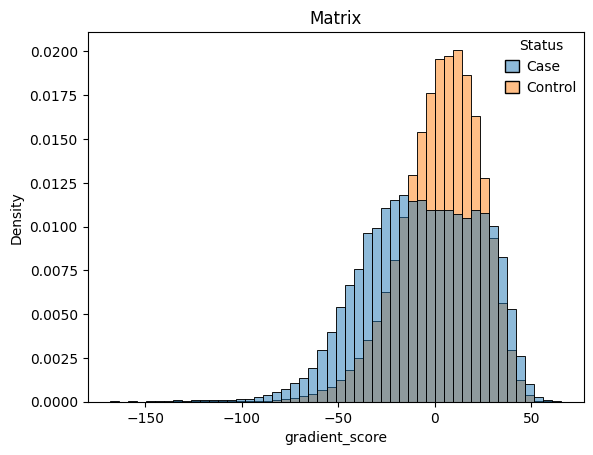

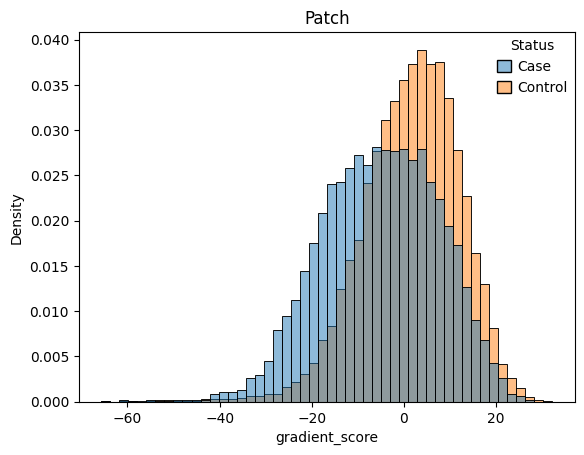

ValueError: No objects to concatenate

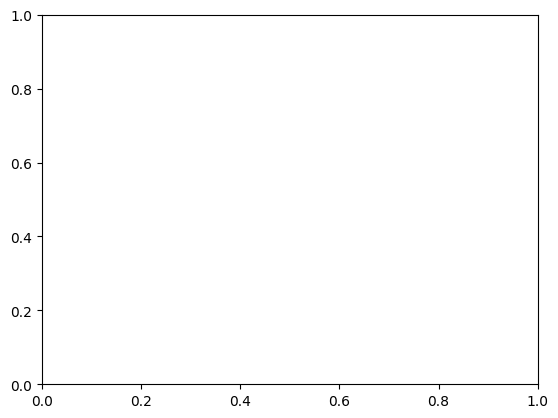

In [ ]:
adata.obs["gradient_score"]

for ct in ["Matrix", "Patch"]:
    sns.histplot(data=adata.obs[adata.obs[CT_FOR_DEG_VARIABLE] == ct], x="gradient_score", hue=CONTRAST_VARIABLE, bins=50, stat="density", common_norm=False); plt.title(ct); plt.show()  


# Define functions

## Nebula Gene Filtering & PCA Stopping Criteria

### Gene Filtering
1. Drop donors with < `min_cells_per_sample` cells.  
2. Keep genes expressed in ≥ `n_donors × min_cells_per_sample` cells.  
3. Keep genes with ≥ `min_counts` total counts.  
4. Skip analysis if:
   - Any condition has < `MIN_SAMPLES_PER_CONDITION` donors.  
   - Remaining genes ≤ `MIN_NUMBER_GENES_PER_ANALYSIS`.  

# Run for all ct

In [5]:
# sc.pl.umap(adata_ct, color=[CONTRAST_VARIABLE, "Group_name", "vireo_prob_doublet"], palette="tab20")
# pcs = [c for c in adata_ct.obs.columns if c.startswith("PC_")]
# DEG.check_corr_cov_in_design(adata_ct, vars_in_formula=[CONTRAST_VARIABLE, *pcs, *COVARIATES_FOR_DEG], corr_thr=0.7, split=" + ")

sorted(adata.obs[CT_FOR_DEG_VARIABLE].unique().tolist())[:2]

['ACx_MEIS2_GABA', 'Activated_Pericytes']



######################
 ACx_MEIS2_GABA 
######################

True
AnnData object with n_obs × n_vars = 633 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_c

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Retained donors : 24
Filtered genes  : 36943 -> 1705 (min_cells=240, min_counts=50)
ERROR: Too few genes filtered out after gene filtering 


######################
 Astrocyte 
######################



/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 118145 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone',

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 118145 cells, 16989 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


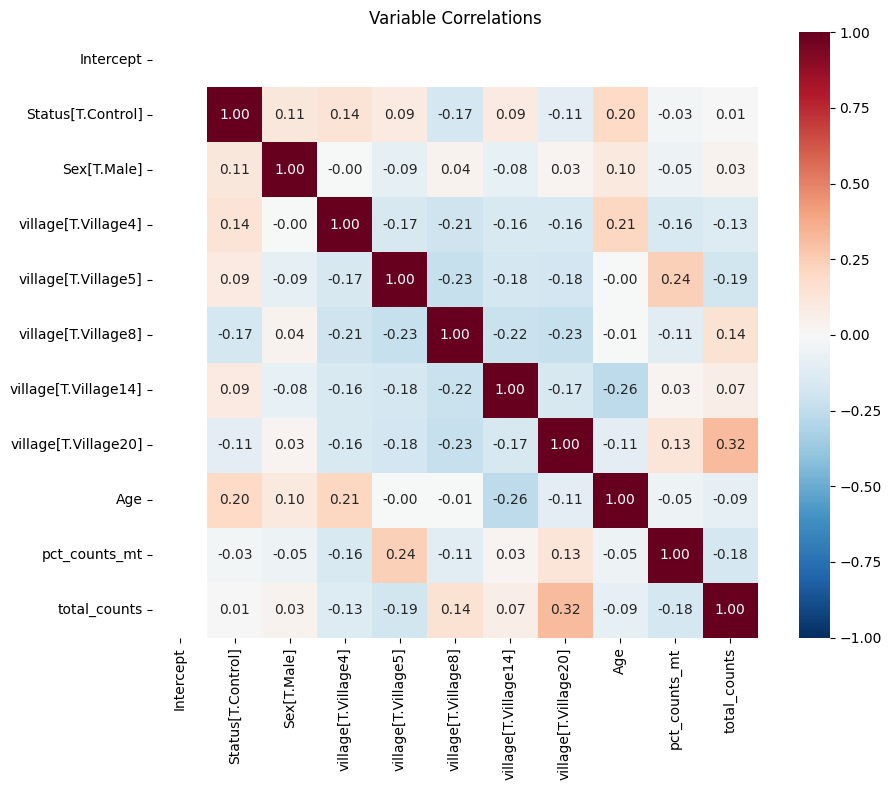

                variable        VIF
0              Intercept  26.979154
7   village[T.Village20]   1.886725
5    village[T.Village8]   1.831290
6   village[T.Village14]   1.731602
4    village[T.Village5]   1.669904
3    village[T.Village4]   1.481694
10          total_counts   1.311591
8                    Age   1.198974
9          pct_counts_mt   1.184240
1      Status[T.Control]   1.142519
2            Sex[T.Male]   1.045630

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...


2026-10-15 17:46:16 | [WARNING] R callback write-console: Loading required package: SeuratObject
  
2026-10-15 17:46:16 | [WARNING] R callback write-console: Loading required package: sp
  
2026-10-15 17:46:18 | [WARNING] R callback write-console: 
Attaching package: ‘SeuratObject’

  
2026-10-15 17:46:18 | [WARNING] R callback write-console: The following objects are masked from ‘package:base’:

    %||%, intersect, t

  



    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    

2026-10-15 17:46:21 | [WARNING] R callback write-console: 
Attaching package: ‘Seurat’

  
2026-10-15 17:46:21 | [WARNING] R callback write-console: The following object is masked from ‘package:base’:

    %||%

  
2026-10-15 17:46:21 | [WARNING] R callback write-console: qs 0.27.3. Announcement: https://github.com/qsbase/qs/issues/103
  



Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 17:48:34 | [WARNING] R callback write-console: Warning:  
2026-10-15 17:48:34 | [WARNING] R callback write-console:  Feature names cannot have underscores ('_'), replacing with dashes ('-')
  
2026-10-15 17:48:34 | [WARNING] R callback write-console: Warning:  
2026-10-15 17:48:34 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


... (3 outputs left out)

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
... storing 'ct_for_deg' as categorical
... storing 'village' as categorical


Retained donors : 53
Filtered genes  : 36943 -> 5054 (min_cells=530, min_counts=50)
Running Factor calculation on Healthy...
Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 1120 cells, 5054 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


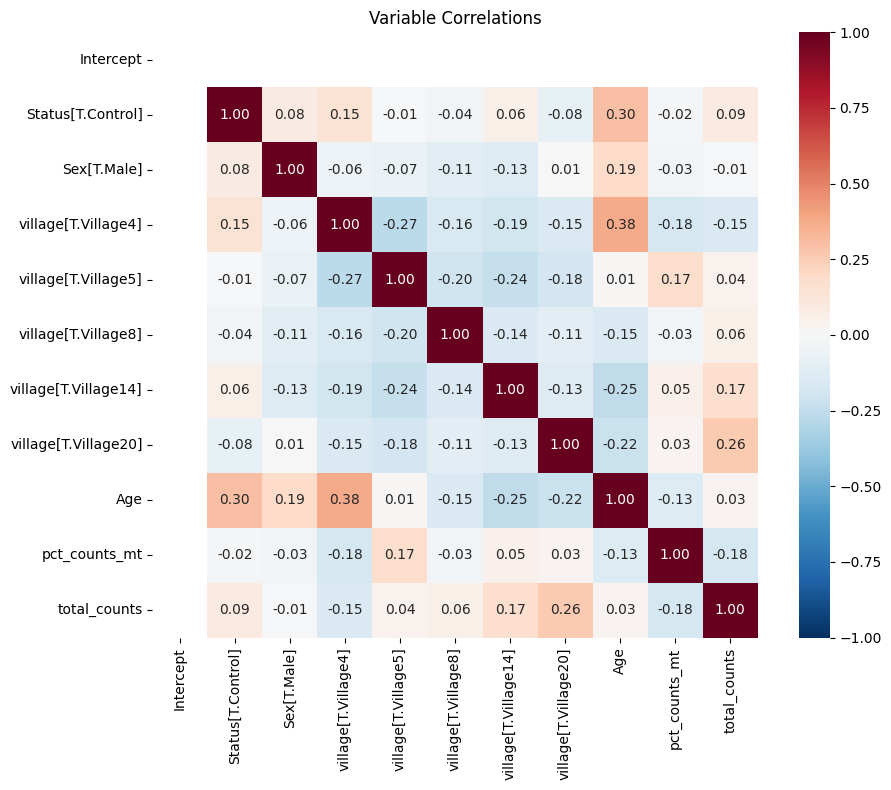

                variable        VIF
0              Intercept  25.128518
6   village[T.Village14]   1.864585
4    village[T.Village5]   1.831567
3    village[T.Village4]   1.672794
7   village[T.Village20]   1.647789
8                    Age   1.558104
5    village[T.Village8]   1.518877
10          total_counts   1.355591
2            Sex[T.Male]   1.159736
1      Status[T.Control]   1.145619
9          pct_counts_mt   1.132732

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:02:29 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:02:29 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Cholinergic_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Cholinergic_GABA_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Cholinergic_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Cholinergic_GABA_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Cholinergic_GABA/tmp_HD_Handsaker_me

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 4740 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', '

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


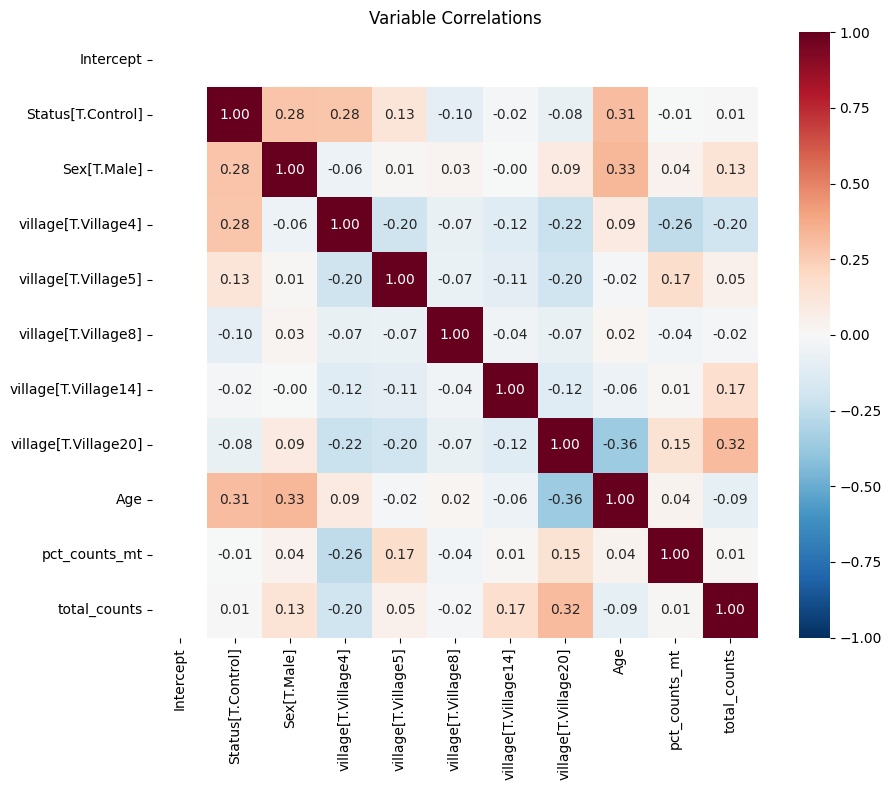

                variable        VIF
0              Intercept  25.138504
7   village[T.Village20]   1.728028
8                    Age   1.529921
3    village[T.Village4]   1.416144
1      Status[T.Control]   1.357933
4    village[T.Village5]   1.338700
2            Sex[T.Male]   1.266234
10          total_counts   1.235040
6   village[T.Village14]   1.177728
9          pct_counts_mt   1.141017
5    village[T.Village8]   1.042352

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:03:32 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:03:32 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Ependymal/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Ependymal_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Ependymal/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Ependymal_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Ependymal/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 1879 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', '

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 65762 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 65755 cells, 19081 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


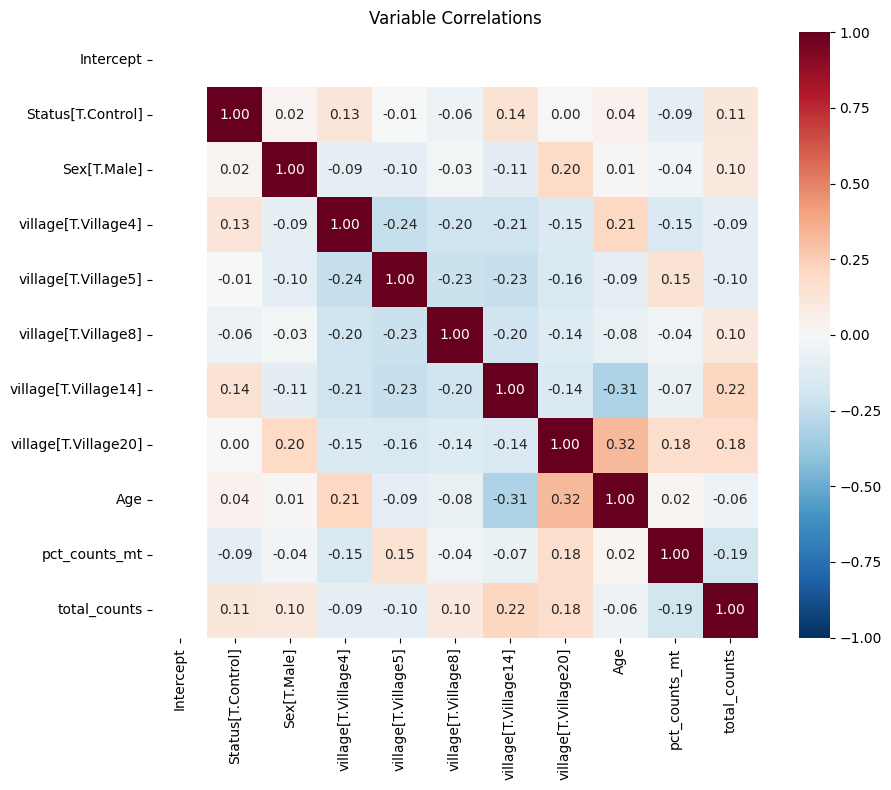

                variable        VIF
0              Intercept  39.291184
6   village[T.Village14]   1.988730
4    village[T.Village5]   1.819788
3    village[T.Village4]   1.755186
5    village[T.Village8]   1.682623
7   village[T.Village20]   1.654646
8                    Age   1.299586
10          total_counts   1.246594
9          pct_counts_mt   1.148175
2            Sex[T.Male]   1.125257
1      Status[T.Control]   1.090028

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:08:26 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:08:26 | [WARNING] R callback write-console:  Feature names cannot have underscores ('_'), replacing with dashes ('-')
  
2026-10-15 18:08:26 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:08:26 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Matrix_D1_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Matrix_D1_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 57743 cells, 18473 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


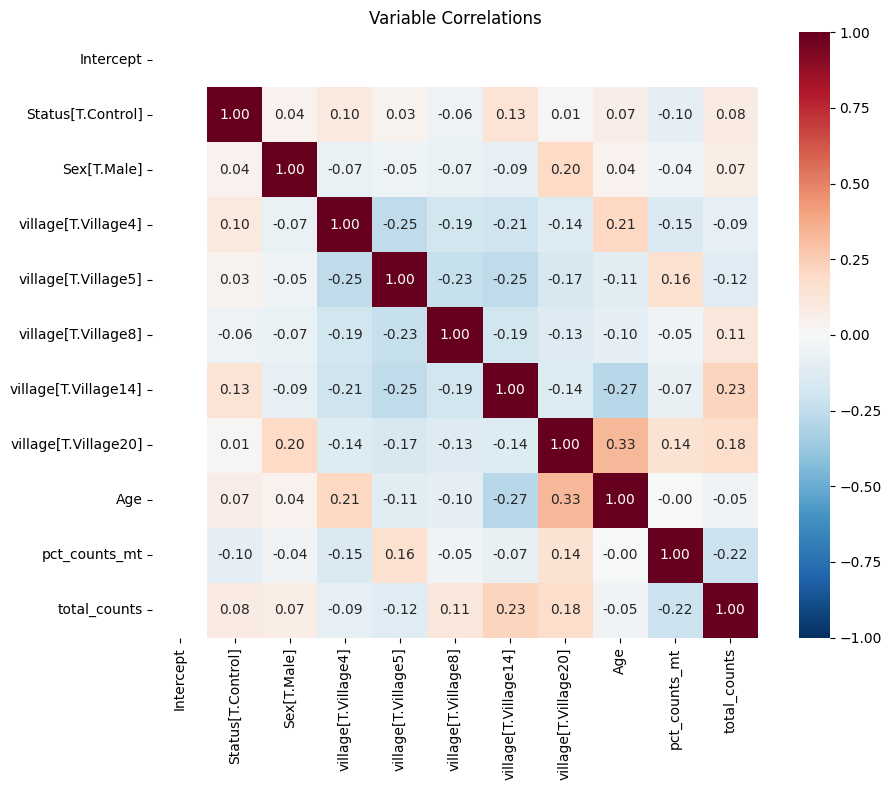

                variable        VIF
0              Intercept  39.306395
6   village[T.Village14]   1.959997
4    village[T.Village5]   1.844843
3    village[T.Village4]   1.705904
5    village[T.Village8]   1.652304
7   village[T.Village20]   1.611455
8                    Age   1.297310
10          total_counts   1.247079
9          pct_counts_mt   1.152194
1      Status[T.Control]   1.095395
2            Sex[T.Male]   1.090102

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:21:57 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:21:57 | [WARNING] R callback write-console:  Feature names cannot have underscores ('_'), replacing with dashes ('-')
  
2026-10-15 18:21:57 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:21:57 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Matrix_D2_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Matrix_D2_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Matrix_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 33609 cells, 9262 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


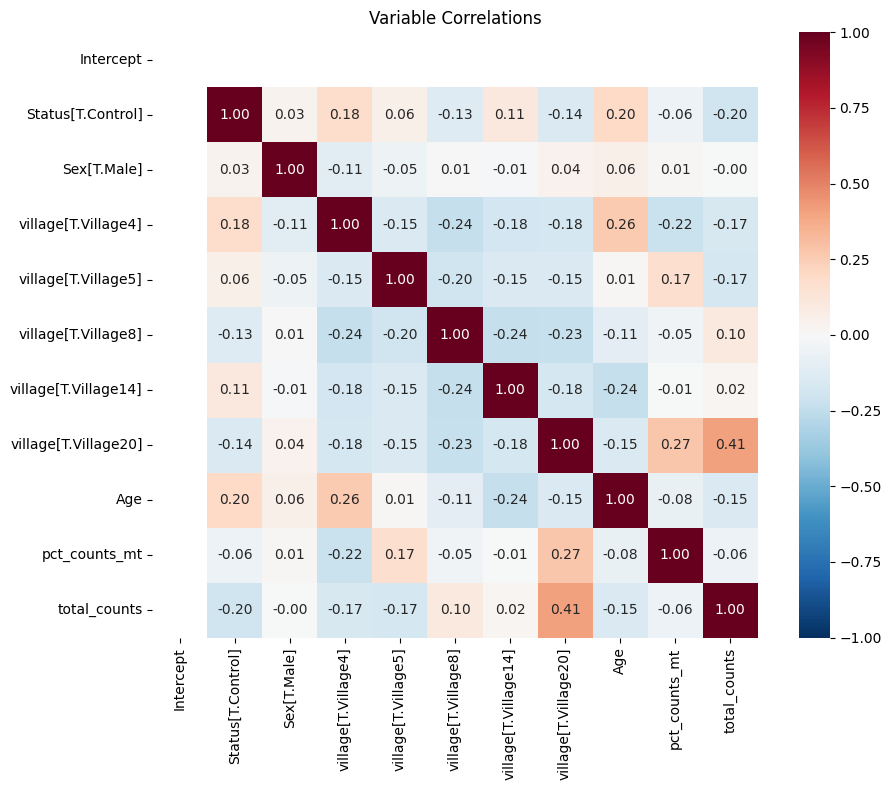

                variable        VIF
0              Intercept  30.012394
7   village[T.Village20]   2.180196
5    village[T.Village8]   1.913018
6   village[T.Village14]   1.816492
3    village[T.Village4]   1.614693
4    village[T.Village5]   1.534272
10          total_counts   1.398160
8                    Age   1.261842
9          pct_counts_mt   1.236285
1      Status[T.Control]   1.142121
2            Sex[T.Male]   1.034095

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:31:01 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:31:01 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Microglia/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Microglia_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Microglia/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Microglia_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Microglia/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 28574 cells, 11164 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


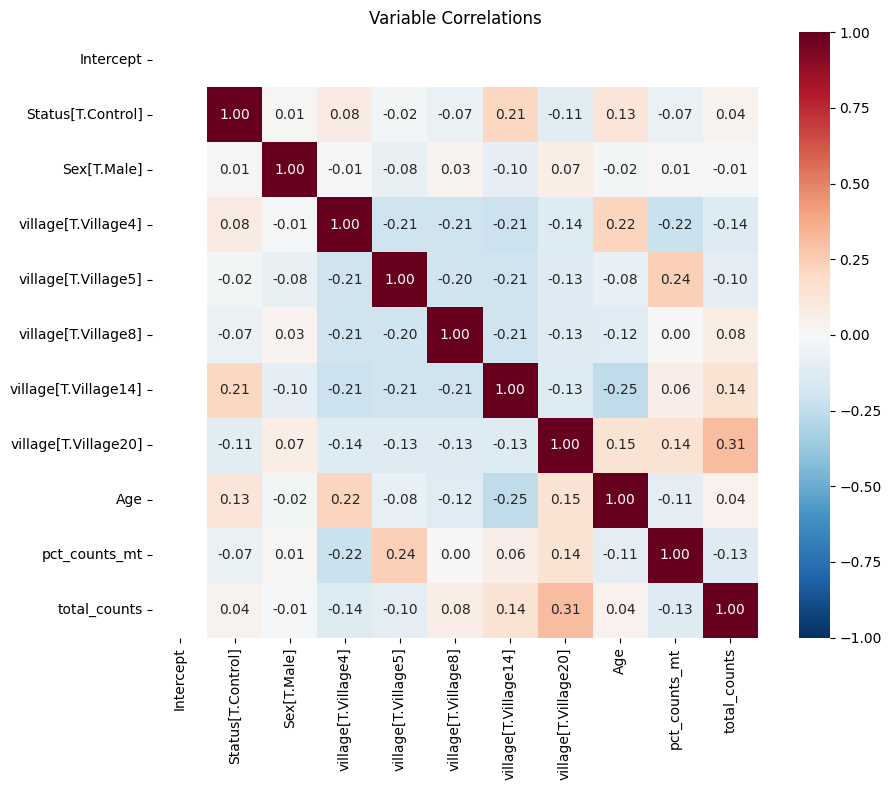

                variable        VIF
0              Intercept  32.397172
6   village[T.Village14]   1.815413
4    village[T.Village5]   1.608695
5    village[T.Village8]   1.540328
7   village[T.Village20]   1.515439
3    village[T.Village4]   1.488405
10          total_counts   1.267295
9          pct_counts_mt   1.226138
8                    Age   1.221494
1      Status[T.Control]   1.123596
2            Sex[T.Male]   1.036086

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:35:16 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:35:16 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/OPC/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_OPC_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/OPC/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_OPC_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/OPC/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_OPC_for_nebula.qs --id-col DO

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 99841 cells, 12615 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


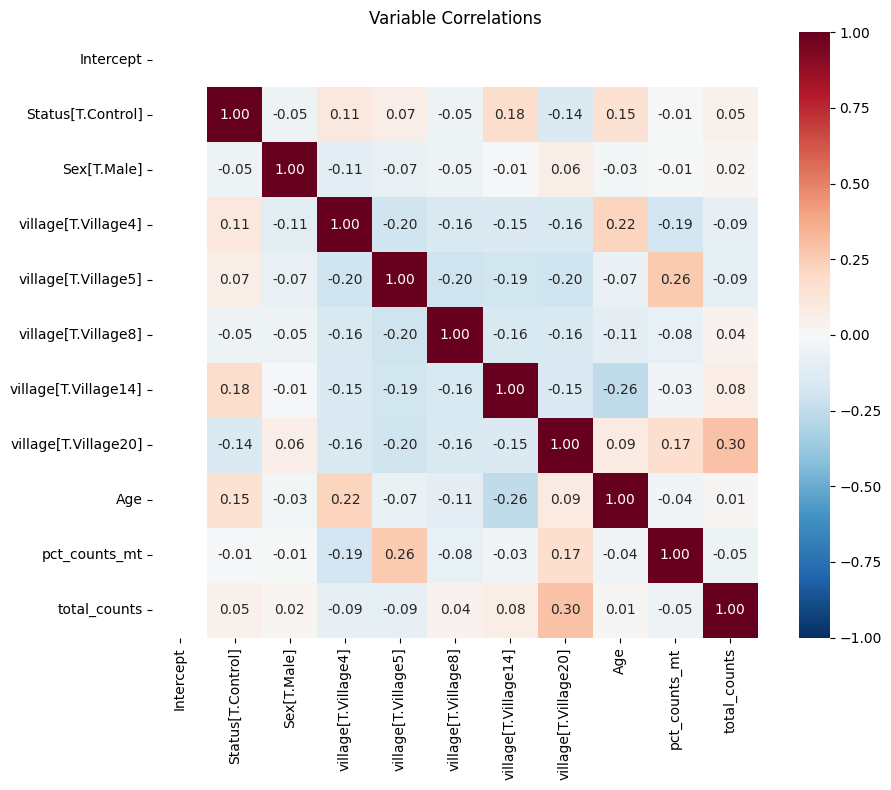

                variable        VIF
0              Intercept  28.042393
4    village[T.Village5]   1.606762
7   village[T.Village20]   1.554918
6   village[T.Village14]   1.536447
5    village[T.Village8]   1.407167
3    village[T.Village4]   1.406406
8                    Age   1.205856
9          pct_counts_mt   1.163712
10          total_counts   1.158004
1      Status[T.Control]   1.136575
2            Sex[T.Male]   1.040704

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:40:56 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:40:56 | [WARNING] R callback write-console:  Feature names cannot have underscores ('_'), replacing with dashes ('-')
  
2026-10-15 18:40:56 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:40:56 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Oligodendrocyte/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Oligodendrocyte_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Oligodendrocyte/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Oligodendrocyte_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Oligodendrocyte/tmp_HD_Handsaker_merged_

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 18125 cells, 14829 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


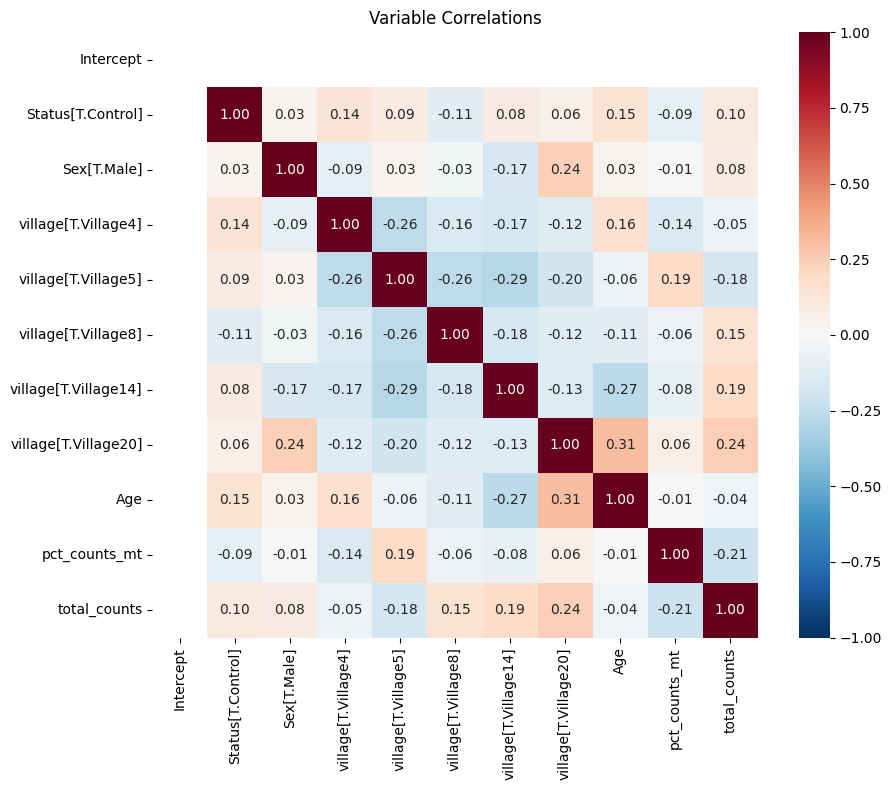

                variable        VIF
0              Intercept  38.369486
4    village[T.Village5]   2.017031
6   village[T.Village14]   1.962944
7   village[T.Village20]   1.669489
5    village[T.Village8]   1.653535
3    village[T.Village4]   1.632567
10          total_counts   1.286504
8                    Age   1.273765
1      Status[T.Control]   1.144270
9          pct_counts_mt   1.121727
2            Sex[T.Male]   1.114175

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:55:02 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:55:02 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patch_D1_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patch_D1_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D1/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patc

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 13358 cells, 13150 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


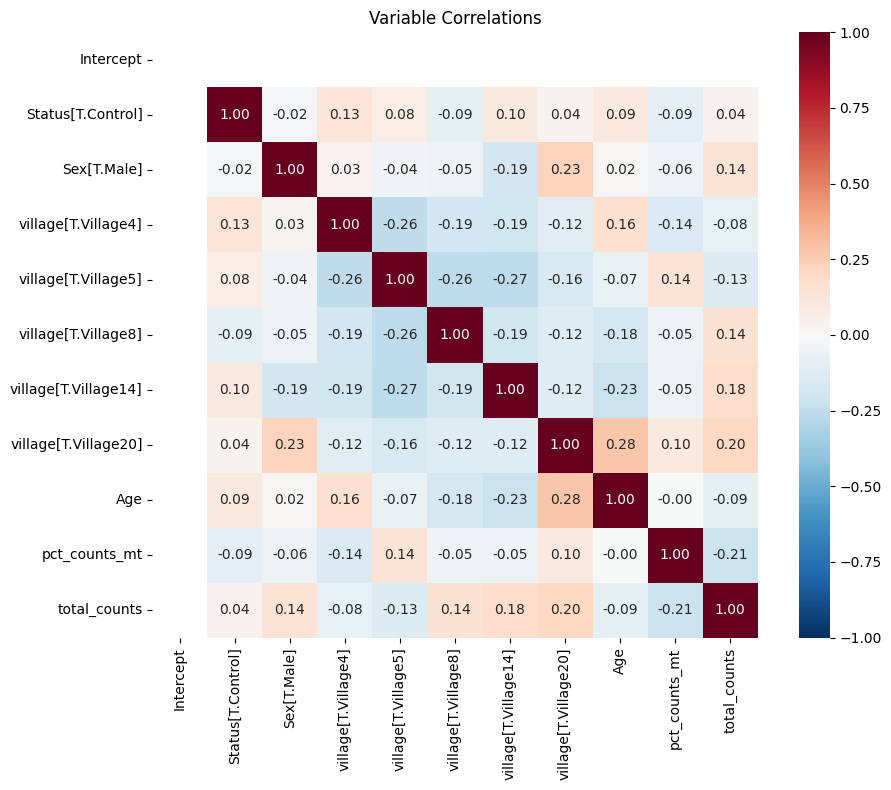

                variable        VIF
0              Intercept  41.356169
6   village[T.Village14]   1.990558
4    village[T.Village5]   1.958218
5    village[T.Village8]   1.784848
3    village[T.Village4]   1.656506
7   village[T.Village20]   1.518260
10          total_counts   1.263655
8                    Age   1.257610
2            Sex[T.Male]   1.145231
9          pct_counts_mt   1.122614
1      Status[T.Control]   1.111444

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 18:58:37 | [WARNING] R callback write-console: Warning:  
2026-10-15 18:58:37 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patch_D2_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patch_D2_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/Patch_D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_Patc

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 11163 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', 

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 11152 cells, 11748 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


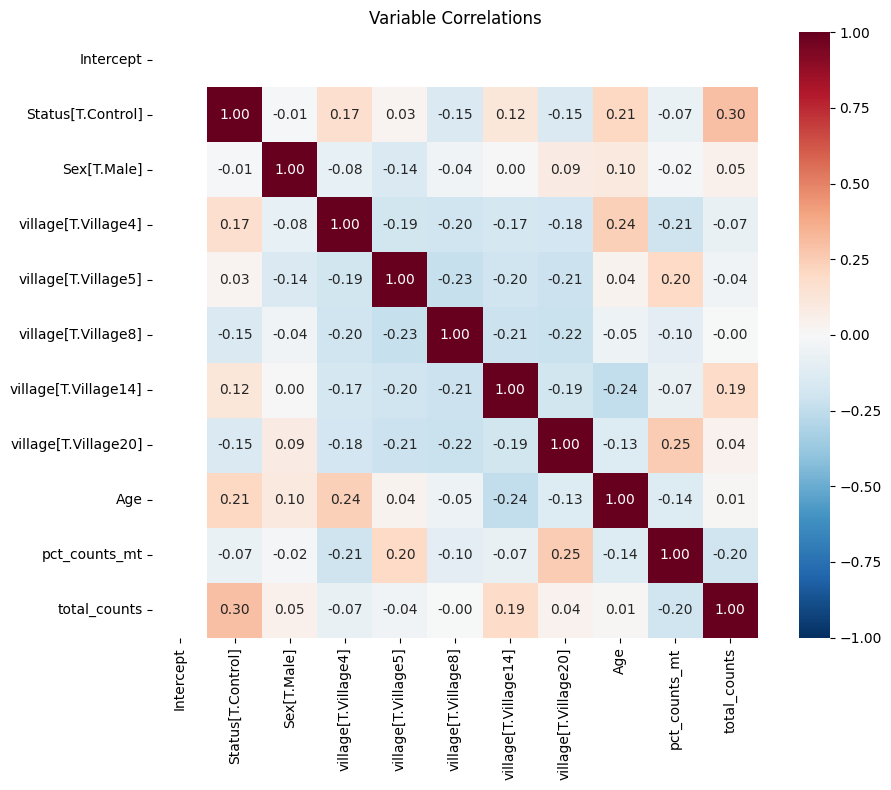

                variable        VIF
0              Intercept  28.730102
7   village[T.Village20]   1.971004
6   village[T.Village14]   1.941655
4    village[T.Village5]   1.938526
5    village[T.Village8]   1.923320
3    village[T.Village4]   1.710501
10          total_counts   1.253131
1      Status[T.Control]   1.251805
9          pct_counts_mt   1.250127
8                    Age   1.236682
2            Sex[T.Male]   1.079970

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:01:24 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:01:24 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_FS_PTHLH-PVALB_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_FS_PTHLH-PVALB_GABA_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_FS_PTHLH-PVALB_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_FS_PTHLH-PVALB_GABA_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_FS_P

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 1913 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', '

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


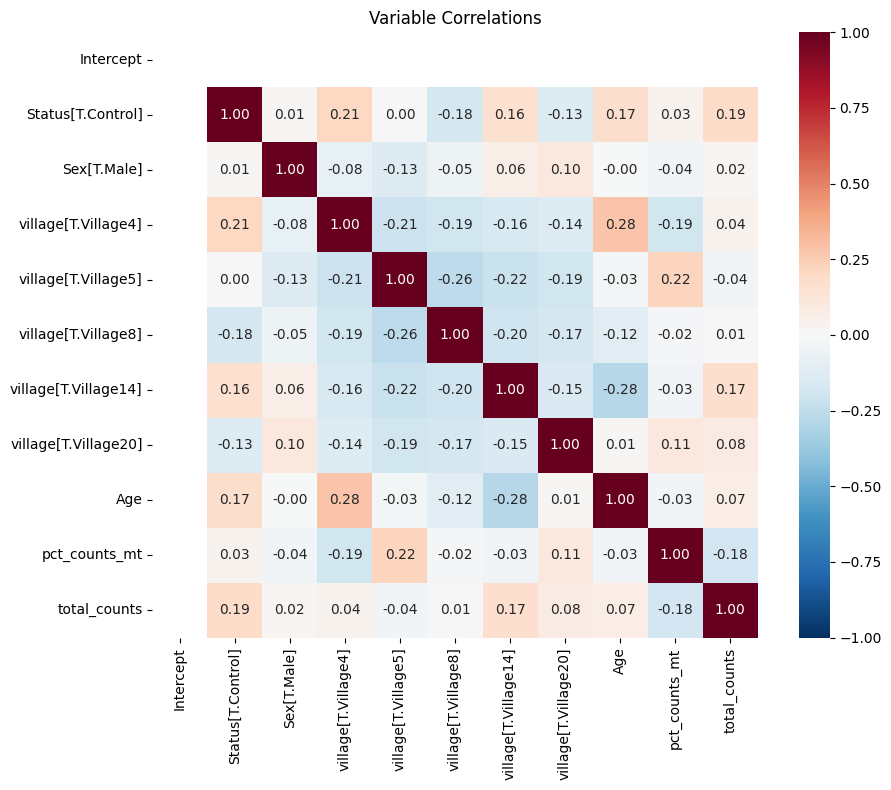

                variable        VIF
0              Intercept  29.843276
4    village[T.Village5]   1.896698
6   village[T.Village14]   1.843088
5    village[T.Village8]   1.784462
3    village[T.Village4]   1.600815
7   village[T.Village20]   1.552840
8                    Age   1.256843
1      Status[T.Control]   1.197335
10          total_counts   1.192521
9          pct_counts_mt   1.168905
2            Sex[T.Male]   1.049039

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:03:31 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:03:31 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_SST-CHODL_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_SST-CHODL_GABA_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_SST-CHODL_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_SST-CHODL_GABA_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_SST-CHODL_GABA/tmp_HD_Ha

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 9654 cells, 10299 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


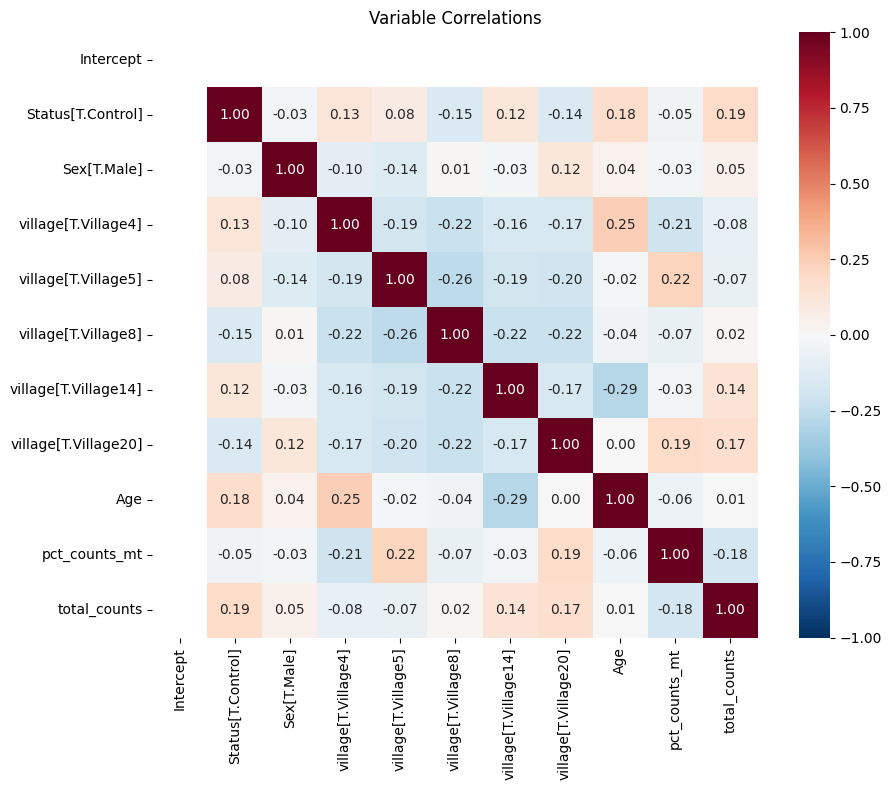

                variable        VIF
0              Intercept  30.015903
5    village[T.Village8]   1.981534
4    village[T.Village5]   1.956647
6   village[T.Village14]   1.890811
7   village[T.Village20]   1.883622
3    village[T.Village4]   1.704281
10          total_counts   1.214816
9          pct_counts_mt   1.211954
8                    Age   1.209232
1      Status[T.Control]   1.173922
2            Sex[T.Male]   1.065612

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:04:57 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:04:57 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_TAC3_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_TAC3_GABA_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_TAC3_GABA/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_STR_TAC3_GABA_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/STR_TAC3_GABA/tmp_HD_Handsaker_merged_labelled_z

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Retained donors : 2
Filtered genes  : 36943 -> 24 (min_cells=20, min_counts=50)

ERROR: Insufficient donors per condition (threshold=4):
  Control               n_donors=1 ← BELOW THRESHOLD
  Case                  n_donors=1 ← BELOW THRESHOLD
Skipping this cell type — NEBULA random effects will be unreliable.



######################
 VIP_GABA 
######################

True
AnnData object with n_obs × n_vars = 1709 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_p

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


True
AnnData object with n_obs × n_vars = 6885 × 36943
    obs: 'reaction', 'experiment', 'CELL_BARCODE', 'DONOR', 'SID', 'Age', 'Sex', 'Status', 'CAG', 'PMI', 'VS_Grade', 'Onset/Motor', 'Onset/Cog', 'CAP', 'CAP-100', 'CAGLENGTH', 'CATEGORY', 'Neighborhood_label', 'Neighborhood_name', 'Neighborhood_bootstrapping_probability', 'Neighborhood_aggregate_probability', 'Neighborhood_correlation_coefficient', 'Class_label', 'Class_name', 'Class_bootstrapping_probability', 'Class_aggregate_probability', 'Class_correlation_coefficient', 'Subclass_label', 'Subclass_name', 'Subclass_bootstrapping_probability', 'Subclass_aggregate_probability', 'Subclass_correlation_coefficient', 'Group_label', 'Group_name', 'Group_bootstrapping_probability', 'Group_aggregate_probability', 'Group_correlation_coefficient', 'Cluster_label', 'Cluster_name', 'Cluster_alias', 'Cluster_bootstrapping_probability', 'Cluster_aggregate_probability', 'Cluster_correlation_coefficient', 'mapping_coupling_for_zoning', 'zone', '

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 6807 cells, 10965 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical
... storing 'village' as categorical
/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


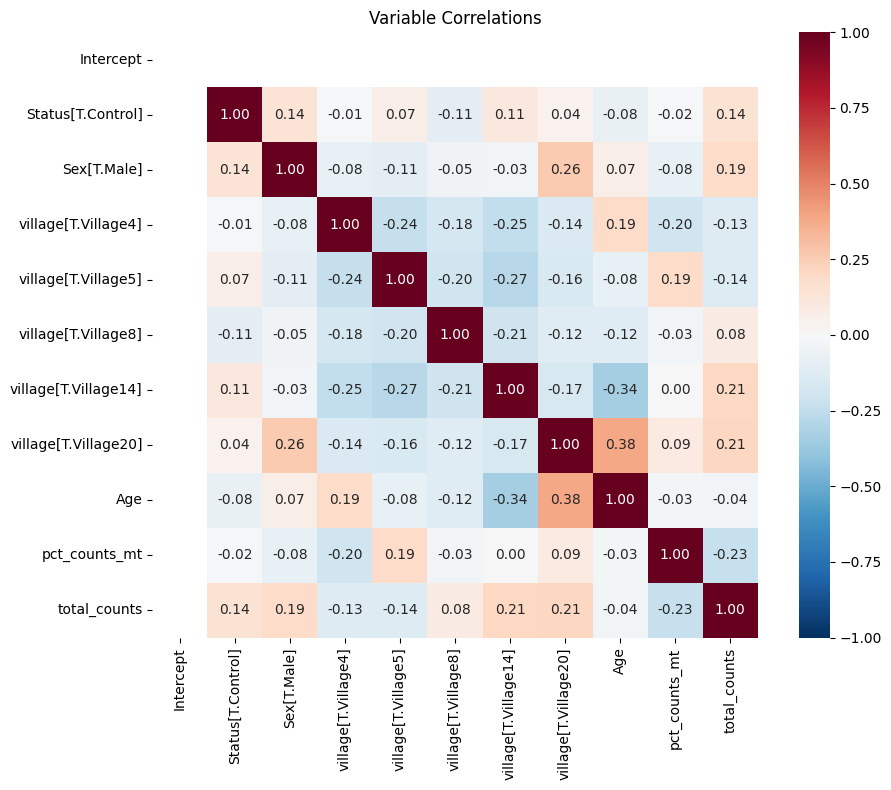

                variable        VIF
0              Intercept  52.731925
6   village[T.Village14]   2.131796
4    village[T.Village5]   1.872393
3    village[T.Village4]   1.725758
7   village[T.Village20]   1.714437
5    village[T.Village8]   1.640924
8                    Age   1.395935
10          total_counts   1.297043
9          pct_counts_mt   1.176703
2            Sex[T.Male]   1.143287
1      Status[T.Control]   1.074758

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:07:07 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:07:07 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_D1D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_D1D2_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_D1D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_D1D2_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_D1D2/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
... storing 'ct_for_deg' as categorical
... storing 'village' as categorical


Retained donors : 30
Filtered genes  : 36943 -> 4948 (min_cells=300, min_counts=50)
Running Factor calculation on Healthy...
Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 866 cells, 4948 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


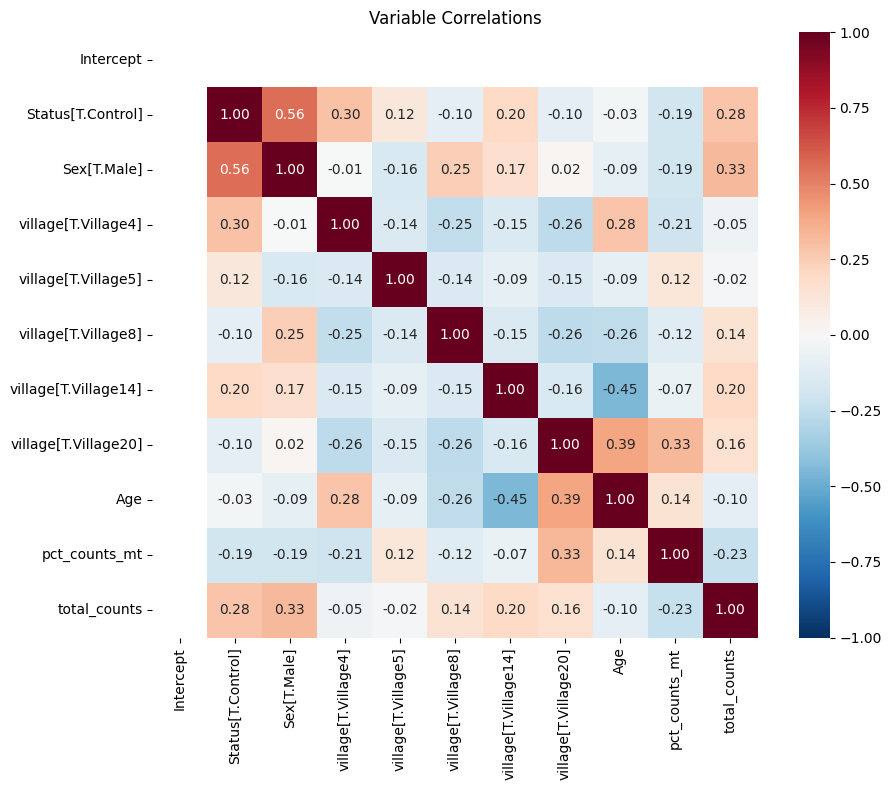

                variable        VIF
0              Intercept  78.963571
7   village[T.Village20]   2.203745
1      Status[T.Control]   2.073875
3    village[T.Village4]   1.955075
2            Sex[T.Male]   1.930882
5    village[T.Village8]   1.865073
8                    Age   1.769176
6   village[T.Village14]   1.765443
4    village[T.Village5]   1.447554
10          total_counts   1.418385
9          pct_counts_mt   1.333628

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:08:41 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:08:41 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_NUDAP/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_NUDAP_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_NUDAP/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_NUDAP_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_NUDAP/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_cu

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]
... storing 'ct_for_deg' as categorical
... storing 'village' as categorical


Retained donors : 42
Filtered genes  : 36943 -> 4571 (min_cells=420, min_counts=50)
Running Factor calculation on Healthy...
Running Factor calculation on Diseased...
Saving h5ad file...
adata intact: 966 cells, 4571 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


/home/gdallagl/myworkdir/XDP/.venv/lib/python3.11/site-packages/anndata/_io/utils.py:243: FutureWarning: Forward slashes will be disallowed in h5 stores in the next minor release
  return func(*args, **kwargs)


~ Status + Age + Sex + pct_counts_mt + village + total_counts


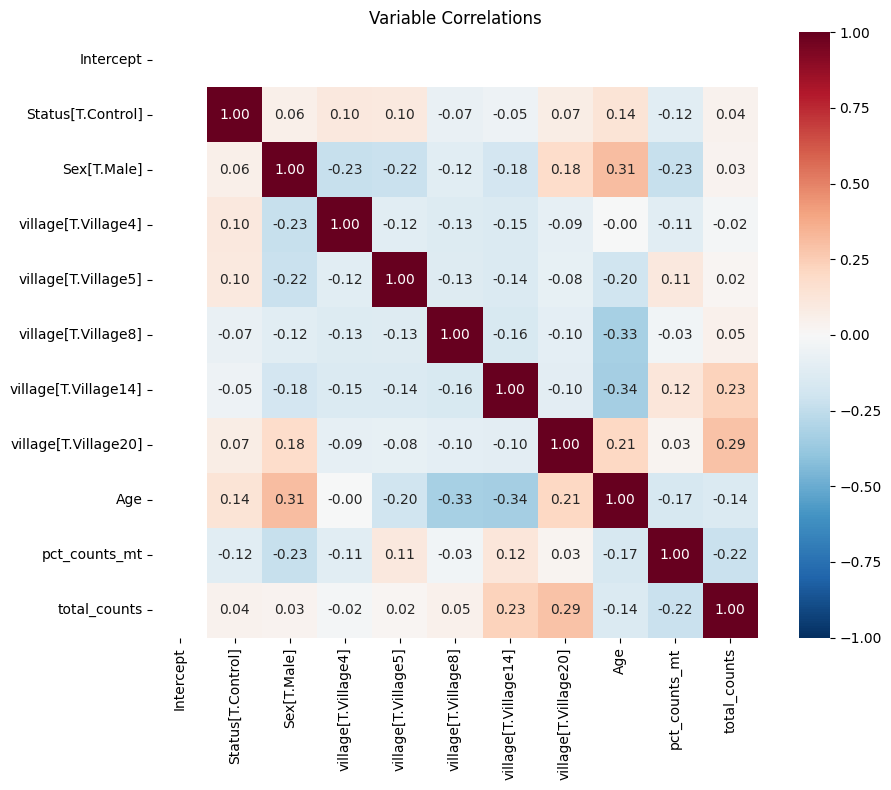

                variable        VIF
0              Intercept  58.973932
6   village[T.Village14]   1.783388
8                    Age   1.743969
5    village[T.Village8]   1.598300
4    village[T.Village5]   1.492926
2            Sex[T.Male]   1.439349
3    village[T.Village4]   1.385486
10          total_counts   1.375157
7   village[T.Village20]   1.281758
9          pct_counts_mt   1.238960
1      Status[T.Control]   1.080465

binary identifiability test. False
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting Status reference level to: Control
Levels: Control Case 
[1] "Creating Seurat object..."


2026-10-15 19:09:36 | [WARNING] R callback write-console: Warning:  
2026-10-15 19:09:36 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_StrioMat/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_StrioMat_for_nebula.qs', '--id-col', 'DONOR', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_StrioMat/tmp_HD_Handsaker_merged_labelled_zoned_VILLAGE_curated_eMSN_StrioMat_for_nebula.qs --id-col DONOR --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/HD_Handsaker/DEG/baseline_nebula/eMSN_StrioMat/tmp_HD_Handsaker_merged_labelled_z

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:466: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


In [6]:
for ct in sorted(adata.obs[CT_FOR_DEG_VARIABLE].unique().tolist())[:]:

    #ct="Matrix_D1"
    if ct.startswith("-"):
        continue

    print("\n\n######################\n",ct, "\n######################\n")

    # Select single ct
    adata_ct = adata[adata.obs[CT_FOR_DEG_VARIABLE] == ct].to_memory().copy()
    adata_ct.X = adata_ct.layers["counts"].copy() 
    print(np.array_equal(adata_ct.X.data, adata_ct.X.data.astype(int)) if hasattr(adata_ct.X, 'data') else np.array_equal(adata_ct.X, adata_ct.X.astype(int)))

    # adata_ct = adata_ct[adata_ct.obs["zone"].isin(["4"])].copy() # only keep control and XDP for this analsys
    print(adata_ct)

    # Define saving apthjs
    ADATA_PATH_QS = f"{DEG_FOLDER}/{ct}/tmp_{os.path.splitext(os.path.basename(ADATA_PATH))[0]}_{ct}_for_nebula.qs"
    SAVE_HEALTHY_PCA_RESULT = os.path.dirname(ADATA_PATH_QS)
    os.makedirs(SAVE_HEALTHY_PCA_RESULT, exist_ok=True)
    print(ADATA_PATH_QS)

    
    CNMF_SPECTRA_PATH = None

    # Delete stale nebula chunks so chunk-sobj-by-genes.R doesn't reuse files
    # from a previous failed run (which had different covariate columns)
    _nebula_dir = f"{os.path.splitext(ADATA_PATH_QS)[0]}__nebula_ln"
    if os.path.exists(_nebula_dir):
        shutil.rmtree(_nebula_dir)

    # Run enire pipeline for this ct
    nebula_utils.run_nebula_with_factors(
        adata_ct, 
        ADATA_PATH_QS, SAVE_HEALTHY_PCA_RESULT, PARALLEL_NEBULA_SCRIPT_PATH,
        CONTRAST_VARIABLE,CONTRAST_BASELINE, CONTRAST_STIM,
        SAMPLE_VARIABLE,LIBRARY_SIZE_COL,COVARIATES_FOR_DEG,
        N_PCS_TO_USE=None, # default knee method
        variance_threshold=None,delete_tmp_files=True, TYPE_DEG=TYPE_DEG,
        MIN_SAMPLES_PER_CONDITION=4, MIN_NUMBER_GENES_PER_ANALYSIS=3000,
        
        # Attention: spectra file expected to be in fixed place
            #/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/{TISSUE}/cNMF_nebula/{ct}/cNMF_run_healthy/cNMF_spectra.txt
        CNMF_SPECTRA_PATH=CNMF_SPECTRA_PATH
    )

    #break
    

In [ ]:
STOP



######################
 Matrix 
######################

True
/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/PCA_nebula/Matrix/tmp_Striatum_combined_QC_mmc_ct-cured_zoned_Matrix_for_nebula.qs
True
ATTENTION: .X must be raw!
Retained donors : 37
Filtered genes  : 38601 -> 19821 (min_cells=370, min_counts=50)
Running Factor calculation on Healthy...


/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:464: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Normalising
HVG
Scaling
PCA on Healthy
Auto-selected 8 PCs via elbow (13.4% variance explained using 50)
Done.
Running Factor calculation on Diseased...
Normalising
Scaling
PCA on Diseased
Done.
Saving h5ad file...
adata intact: 14838 cells, 19821 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + PC_8 + total_counts


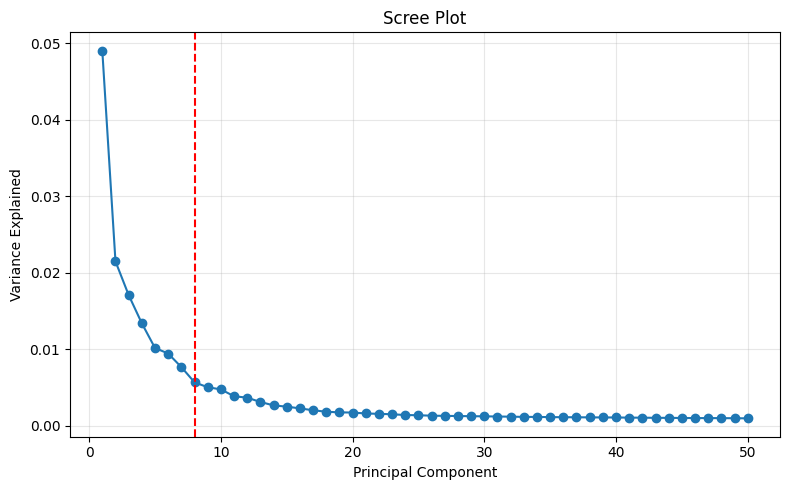

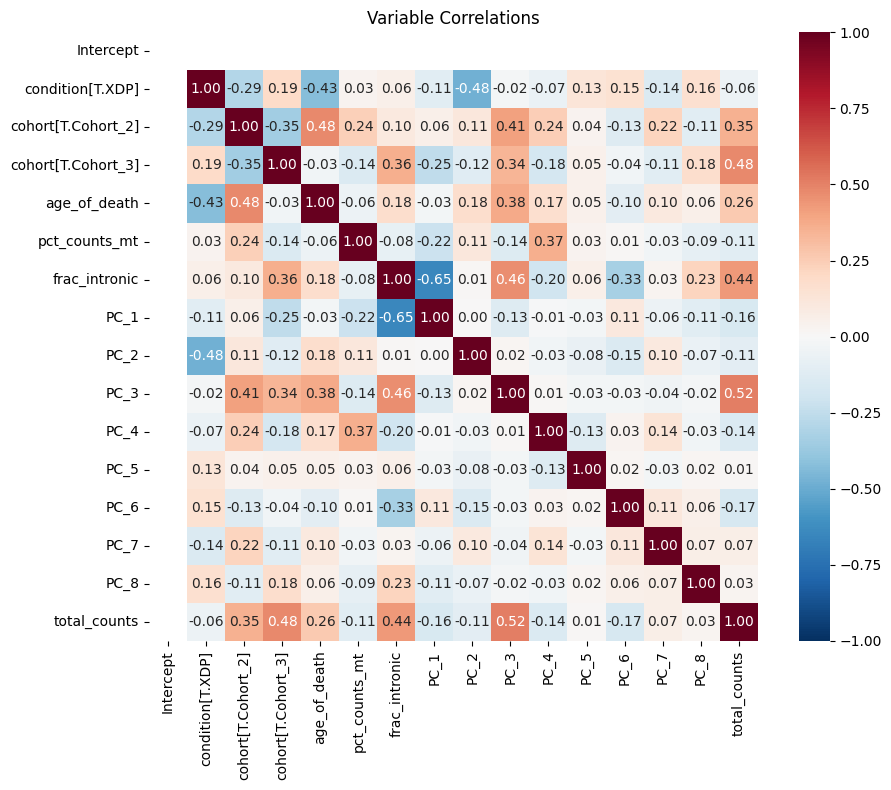

              variable          VIF
0            Intercept  1117.397963
2   cohort[T.Cohort_2]     3.799023
6        frac_intronic     3.585293
3   cohort[T.Cohort_3]     2.928843
9                 PC_3     2.754957
15        total_counts     2.622195
7                 PC_1     2.382421
1     condition[T.XDP]     1.811795
4         age_of_death     1.771971
5        pct_counts_mt     1.703380
10                PC_4     1.480768
8                 PC_2     1.476418
12                PC_6     1.390807
13                PC_7     1.234740
14                PC_8     1.227015
11                PC_5     1.106538

binary identifiability test. False


2026-06-09 13:08:05 | [WARNING] R callback write-console: condition: factor | example: XDP
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: donor_id: character | example: SCF-18-004
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: age_of_death: numeric | example: 56
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.0388265746333046
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.762041613978618
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: PC_1: numeric | example: 2.44017196081234
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: PC_2: numeric | example: -9.95924134668503
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: PC_3: numeric | example: -0.585685256314882
  
2026-06-09 13:08:05 | [WARNING] R callback write-console: PC_4: nume

factor      beta       se  p_value      fdr
  PC_2 -8.158563 1.672842 0.000030 0.000244
  PC_5  1.545288 0.536842 0.007539 0.030157
  PC_8  0.917336 0.829288 0.277647 0.529669
  PC_1 -2.083330 2.045476 0.316097 0.529669
  PC_7 -0.735386 0.744791 0.331043 0.529669
  PC_6  0.623711 1.307891 0.636692 0.788319
  PC_3 -0.395571 1.428427 0.783615 0.788319
  PC_4  0.289678 1.069904 0.788319 0.788319
Saving qs file...
	Saving files for R coversion...


2026-06-09 13:08:13 | [WARNING] R callback write-console: Loading required package: SeuratObject
  
2026-06-09 13:08:13 | [WARNING] R callback write-console: Loading required package: sp
  


	Building R obj...


2026-06-09 13:08:14 | [WARNING] R callback write-console: 
Attaching package: ‘SeuratObject’

  
2026-06-09 13:08:14 | [WARNING] R callback write-console: The following objects are masked from ‘package:base’:

    %||%, intersect, t

  


... (5 outputs left out)

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:464: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Normalising
HVG
Scaling
PCA on Healthy
Auto-selected 9 PCs via elbow (14.2% variance explained using 50)
Done.
Running Factor calculation on Diseased...
Normalising
Scaling
PCA on Diseased
Done.
Saving h5ad file...
adata intact: 5058 cells, 16006 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + PC_1 + PC_2 + PC_3 + PC_4 + PC_5 + PC_6 + PC_7 + PC_8 + PC_9 + total_counts


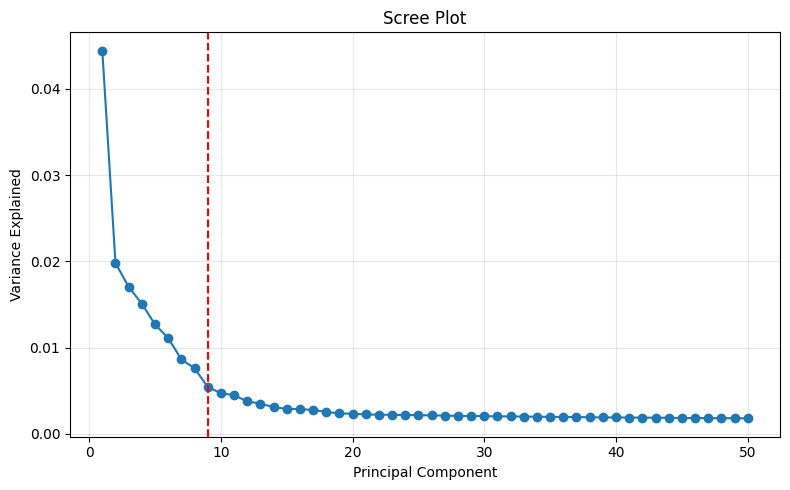

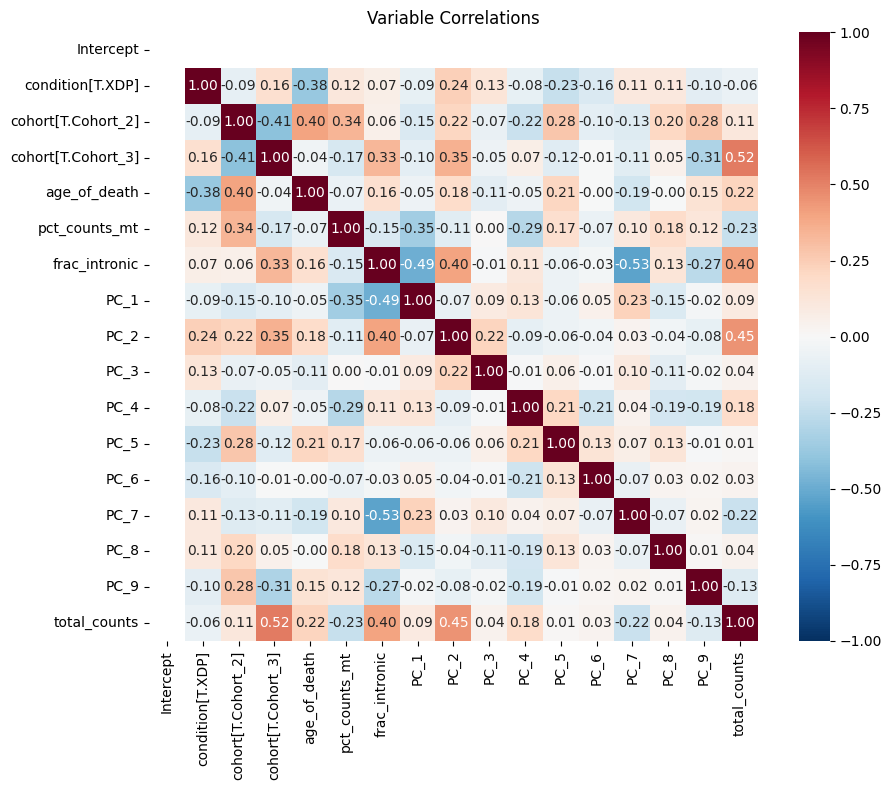

2026-06-09 13:13:51 | [WARNING] R callback write-console: condition: factor | example: XDP
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: donor_id: character | example: SCF-20-025
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: age_of_death: numeric | example: 54
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.114463249121086
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.725174287113246
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: PC_1: numeric | example: 5.09677932447435
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: PC_2: numeric | example: 1.68459998342984
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: PC_3: numeric | example: 11.7910465384106
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: PC_4: numeric 

              variable          VIF
0            Intercept  1162.133108
6        frac_intronic     3.467754
2   cohort[T.Cohort_2]     3.308764
3   cohort[T.Cohort_3]     3.078583
16        total_counts     2.531439
8                 PC_2     2.472272
7                 PC_1     2.124745
13                PC_7     1.862756
5        pct_counts_mt     1.729242
10                PC_4     1.679216
4         age_of_death     1.583627
11                PC_5     1.534038
1     condition[T.XDP]     1.482336
15                PC_9     1.329439
12                PC_6     1.263321
14                PC_8     1.247204
9                 PC_3     1.241603

binary identifiability test. False


2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_1 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_2 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_3 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_4 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_5 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:51 | [WARNING] R callback write-console: 
Fitting: PC_6 ~ condition + age_of_death + pct_counts_mt + frac_intronic + cohort + (1|donor_id)
  
2026-06-09 13:13:52 | [WARNING] R callback wri

factor      beta       se  p_value      fdr
  PC_5 -2.304761 0.765949 0.005168 0.046513
  PC_3  2.925051 1.535461 0.066177 0.210540
  PC_6 -2.007606 1.069548 0.070180 0.210540
  PC_2  1.951879 1.361526 0.161711 0.337227
  PC_8  1.149493 0.914345 0.218225 0.337227
  PC_4 -1.281951 1.035092 0.224818 0.337227
  PC_7  0.853641 1.007025 0.403107 0.518281
  PC_1 -0.706859 2.115834 0.740569 0.833140
  PC_9  0.037301 0.569447 0.948194 0.948194
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting condition reference level to: Control
Levels: Control XDP 
[1] "Creating Seurat object..."


2026-06-09 13:14:10 | [WARNING] R callback write-console: Warning:  
2026-06-09 13:14:10 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/PCA_nebula/Patch/tmp_Striatum_combined_QC_mmc_ct-cured_zoned_Patch_for_nebula.qs', '--id-col', 'donor_id', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/PCA_nebula/Patch/tmp_Striatum_combined_QC_mmc_ct-cured_zoned_Patch_for_nebula.qs --id-col donor_id --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/PCA_nebula/Patch/tmp_Striatum_combined_QC_mmc_ct-cured_zoned_Patch_for_nebula.qs --id-col donor_id --

In [ ]:
# for ct in sorted(adata.obs[CT_FOR_DEG_VARIABLE].unique().tolist())[:]:

#     #ct="Matrix_D1"
#     if ct.startswith("-"):
#         continue

#     if (TYPE_DEG == "cNMF_nebula") and (ct not in ct_forcNMF[TISSUE]):
#         print(f"Skipping {ct} because it's not in the list of cell types to run cNMF on.")
#         continue

#     print("\n\n######################\n",ct, "\n######################\n")

#     # Select single ct
#     adata_ct = adata[adata.obs[CT_FOR_DEG_VARIABLE] == ct].to_memory().copy()
#     adata_ct.X = adata_ct.layers["counts"].copy() 
#     print(np.array_equal(adata_ct.X.data, adata_ct.X.data.astype(int)) if hasattr(adata_ct.X, 'data') else np.array_equal(adata_ct.X, adata_ct.X.astype(int)))

#     # adata_ct = adata_ct[adata_ct.obs["zone"].isin(["4"])].copy() # only keep control and XDP for this analsys
#     # print(adata_ct)

#     # Define saving apthjs
#     ADATA_PATH_QS = f"{DEG_FOLDER}/{ct}/tmp_{os.path.splitext(os.path.basename(ADATA_PATH))[0]}_{ct}_for_nebula.qs"
#     SAVE_HEALTHY_PCA_RESULT = os.path.dirname(ADATA_PATH_QS)
#     os.makedirs(SAVE_HEALTHY_PCA_RESULT, exist_ok=True)
#     print(ADATA_PATH_QS)

#     #break

#     if TYPE_DEG == "cNMF_nebula":
#         # For cNMF, we need to provide the spectra file path (with gene names as index)
#             # RAW SPECTRA
#         matches = glob.glob(f"/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/{TISSUE}/cNMF_nebula/{ct}/cNMF_run_healthy/*.spectra.*.consensus.txt")
#         if len(matches) == 0:
#             # First time for this tissue/ct: no spectra yet.
#             # run_nebula_with_factors will save healthy_cNMF.h5ad and return None.
#             print(f"No spectra found for {ct} — will save healthy h5ad for cNMF training on UGER.")
#             CNMF_SPECTRA_PATH = None
#         elif len(matches) > 1:
#             raise ValueError(f"Expected 1 spectra file for {ct}, found {len(matches)}: {matches}")
#         else:
#             CNMF_SPECTRA_PATH = matches[0]
#     else:
#         CNMF_SPECTRA_PATH = None


#     # Run enire pipeline for this ct
#     nebula_utils.run_nebula_with_factors(
#         adata_ct, 
#         ADATA_PATH_QS, SAVE_HEALTHY_PCA_RESULT, PARALLEL_NEBULA_SCRIPT_PATH,
#         CONTRAST_VARIABLE,CONTRAST_BASELINE, CONTRAST_STIM,
#         SAMPLE_VARIABLE,LIBRARY_SIZE_COL,COVARIATES_FOR_DEG,
#         N_PCS_TO_USE=None, # default knee method
#         variance_threshold=None,delete_tmp_files=True, TYPE_DEG=TYPE_DEG,
#         MIN_SAMPLES_PER_CONDITION=4, MIN_NUMBER_GENES_PER_ANALYSIS=3000,
        
#         # Attention: spectra file expected to be in fixed place
#             #/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/{TISSUE}/cNMF_nebula/{ct}/cNMF_run_healthy/cNMF_spectra.txt
#         CNMF_SPECTRA_PATH=CNMF_SPECTRA_PATH
#     )

#     #break
    

In [ ]:
adata.obs[adata.obs[CONTRAST_VARIABLE].isna()][SAMPLE_VARIABLE].unique()

[], Categories (41, object): ['PCMC-16-011', 'PCMC-16-012', 'SCF-18-003', 'SCF-18-004', ..., 'SCF_23_072CF', 'SCF_23_074CF', 'SCF_23_075CM', 'SCF_23_079CF']

# Run for all Zones 
### ONLY STR  --> omly tissue with zones
### cNMF in zone uses the data/files of the cell type used for mapping

In [ ]:
if TISSUE != "Striatum":
    exit()

In [ ]:
# Map: cell types that have zone analysis → their zone variable
# each cell type has  a better zonation level
ZONE_CT_MAP = {
    "Matrix_D1": "zone", # just zone for zone_6
    "Matrix_D2": "zone",

    "Patch_D1":  "zone_4",
    "Patch_D2":  "zone_4",
    "eMSN_D1D2": "zone_4",
    "Astrocyte": "zone_4",
}
# adata stays untouched here — no more global mutation


In [ ]:
DEG_FOLDER

'/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/SN/cNMF_nebula'

: 

In [ ]:
ZONE_CT_MAP.items()

dict_items([('Matrix_D1', 'zone'), ('Matrix_D2', 'zone'), ('Patch_D1', 'zone_4'), ('Patch_D2', 'zone_4'), ('eMSN_D1D2', 'zone_4'), ('Astrocyte', 'zone_4')])

Using spectra: /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte/cNMF_run_healthy/healthy_cNMF.spectra.k_12.dt_0_05.consensus.txt


######################
Astrocyte / zone_4=1 / cNMF_nebula
######################

/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/1
True
ATTENTION: .X must be raw!
Retained donors : 47
Filtered genes  : 38601 -> 12878 (min_cells=470, min_counts=50)
Running Factor calculation on Healthy...


/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:461: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Found existing cNMF spectra at /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte/cNMF_run_healthy/healthy_cNMF.spectra.k_12.dt_0_05.consensus.txt, skipping cNMF training and proceeding to projection step.
Saved healthy GEP projections: 1977 cells, 11 GEPs
Running Factor calculation on Diseased...
Saved diseased GEP projections: 6112 cells, 11 GEPs
Saving h5ad file...
adata intact: 8089 cells, 12878 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + total_counts


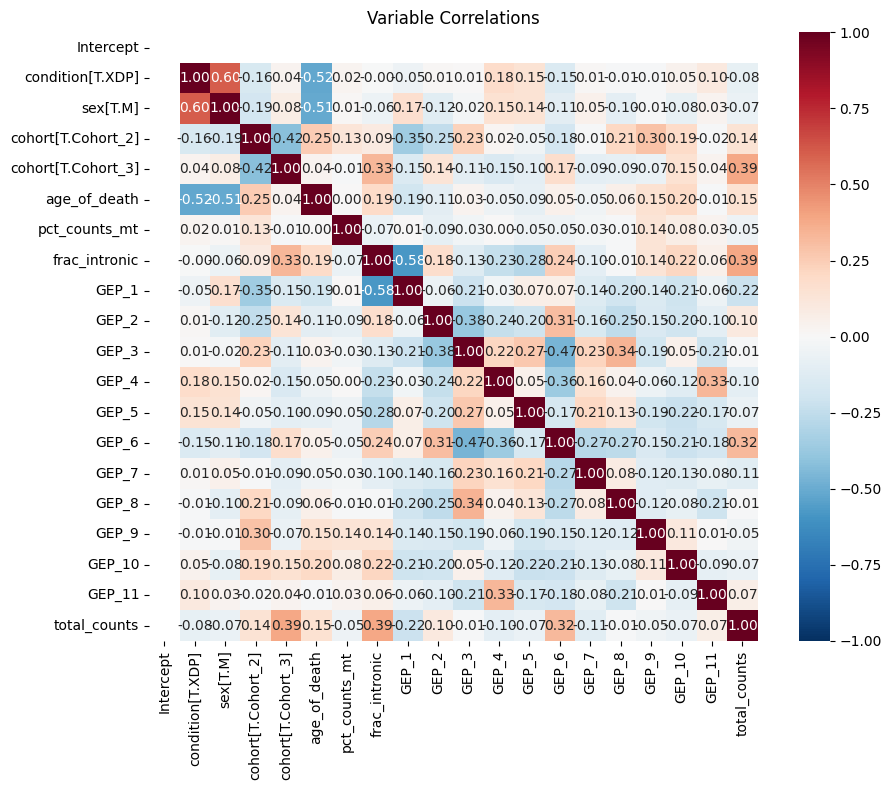

              variable         VIF
0            Intercept  464.954367
13               GEP_6    3.433664
8                GEP_1    2.827076
10               GEP_3    2.700274
17              GEP_10    2.477679
3   cohort[T.Cohort_2]    2.473131
9                GEP_2    2.462106
7        frac_intronic    2.357145
18              GEP_11    2.343027
1     condition[T.XDP]    2.185774
4   cohort[T.Cohort_3]    2.144866
16               GEP_9    2.097945
2             sex[T.M]    2.090622
15               GEP_8    1.930366
19        total_counts    1.824973
5         age_of_death    1.787284
12               GEP_5    1.569213
11               GEP_4    1.568697
14               GEP_7    1.485424
6        pct_counts_mt    1.064202

binary identifiability test. False
ATTENTION: using lmerTest (Gaussian LMM) --> not totally statistically correct (but still robust) 
		 ZIBR coudl be better


2026-04-21 19:28:04 | [WARNING] R callback write-console: condition: factor | example: XDP
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: donor_id: character | example: SCF-20-025
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: age_of_death: numeric | example: 54
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: sex: character | example: M
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.162876852324987
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.679666889164362
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: GEP_1: numeric | example: 0.224756625405671
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: GEP_2: numeric | example: 0.0392135865215256
  
2026-04-21 19:28:04 | [WARNING] R callback write-console: GEP_3: numeric | exampl

factor     beta       se  p_value      fdr
GEP_10 0.098146 0.020377 0.000021 0.000235
 GEP_8 0.060228 0.015796 0.000461 0.002537
 GEP_9 0.065488 0.020323 0.002500 0.008667
 GEP_5 0.033998 0.010854 0.003152 0.008667
 GEP_4 0.022152 0.009326 0.022320 0.048171
 GEP_6 0.041417 0.017977 0.026275 0.048171
 GEP_3 0.046538 0.022976 0.049308 0.077484
GEP_11 0.046749 0.026235 0.082133 0.112933
 GEP_2 0.032440 0.022621 0.159204 0.194582
 GEP_7 0.009721 0.013555 0.477263 0.524990
 GEP_1 0.006494 0.015899 0.685022 0.685022
Significant GEPs (FDR<0.05): ['GEP_10', 'GEP_8', 'GEP_9', 'GEP_5', 'GEP_4', 'GEP_6']
Saving qs file...
	Saving files for R coversion...


2026-04-21 19:28:10 | [WARNING] R callback write-console: Loading required package: SeuratObject
  
2026-04-21 19:28:10 | [WARNING] R callback write-console: Loading required package: sp
  


	Building R obj...


2026-04-21 19:28:11 | [WARNING] R callback write-console: 
Attaching package: ‘SeuratObject’

  
2026-04-21 19:28:11 | [WARNING] R callback write-console: The following objects are masked from ‘package:base’:

    %||%, intersect, t

  


... (5 outputs left out)

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:461: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Found existing cNMF spectra at /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte/cNMF_run_healthy/healthy_cNMF.spectra.k_12.dt_0_05.consensus.txt, skipping cNMF training and proceeding to projection step.
Saved healthy GEP projections: 2668 cells, 11 GEPs
Running Factor calculation on Diseased...
Saved diseased GEP projections: 6765 cells, 11 GEPs
Saving h5ad file...
adata intact: 9433 cells, 13133 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + total_counts


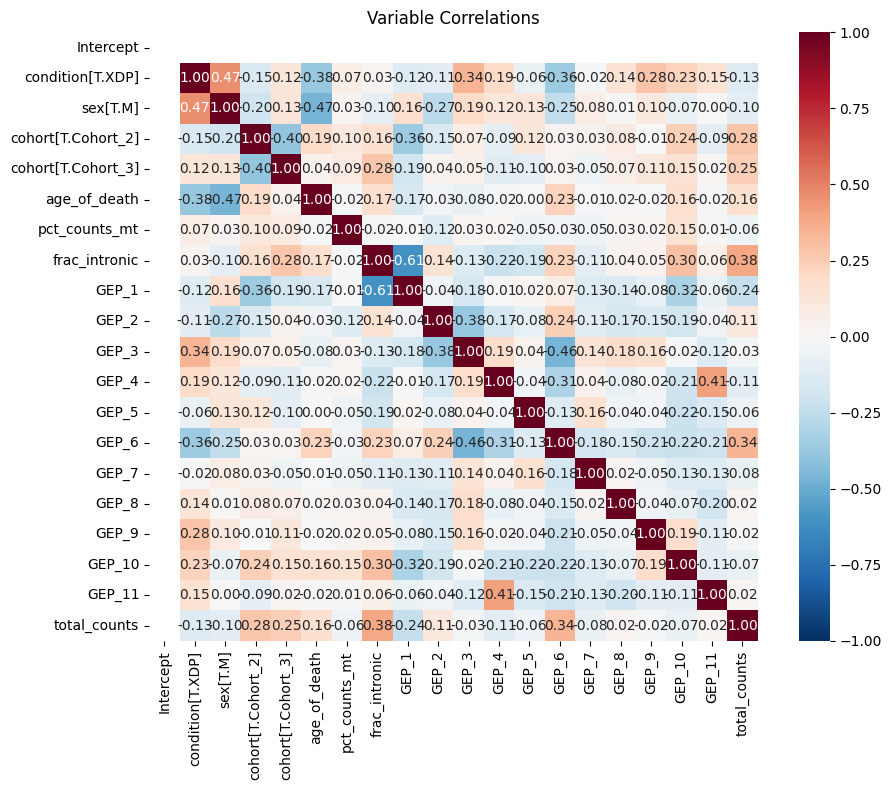

              variable         VIF
0            Intercept  503.198081
17              GEP_10    4.161226
13               GEP_6    3.648289
10               GEP_3    2.916600
8                GEP_1    2.837090
1     condition[T.XDP]    2.831210
18              GEP_11    2.541385
3   cohort[T.Cohort_2]    2.521424
7        frac_intronic    2.397025
9                GEP_2    2.272133
4   cohort[T.Cohort_3]    2.083436
2             sex[T.M]    1.986902
15               GEP_8    1.928329
11               GEP_4    1.788522
19        total_counts    1.773908
5         age_of_death    1.768721
12               GEP_5    1.606974
16               GEP_9    1.440307
14               GEP_7    1.368717
6        pct_counts_mt    1.094718

binary identifiability test. False


2026-04-21 19:31:01 | [WARNING] R callback write-console: condition: factor | example: Control
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: donor_id: character | example: SCF-22-054CM
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: age_of_death: numeric | example: 51
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: sex: character | example: M
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.0280938334035679
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.738555053838138
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: GEP_1: numeric | example: 0.11023022316391
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: GEP_2: numeric | example: 0.070490846427879
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: GEP_3: numeric | e

ATTENTION: using lmerTest (Gaussian LMM) --> not totally statistically correct (but still robust) 
		 ZIBR coudl be better


2026-04-21 19:31:01 | [WARNING] R callback write-console: 
Fitting: GEP_2 ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_3 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + (1|donor_id)
  
2026-04-21 19:31:01 | [WARNING] R callback write-console: 
Fitting: GEP_3 ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + (1|donor_id)
  
2026-04-21 19:31:02 | [WARNING] R callback write-console: 
Fitting: GEP_4 ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + (1|donor_id)
  
2026-04-21 19:31:02 | [WARNING] R callback write-console: 
Fitting: GEP_5 ~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_4 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + (1|donor_id)
  
2026-04-

factor     beta       se  p_value      fdr
GEP_10 0.157942 0.028547 0.000002 0.000022
 GEP_8 0.119063 0.023228 0.000008 0.000042
 GEP_9 0.087419 0.019222 0.000048 0.000176
 GEP_3 0.138291 0.031442 0.000076 0.000210
 GEP_4 0.049825 0.012736 0.000342 0.000746
 GEP_6 0.085825 0.022293 0.000407 0.000746
GEP_11 0.092257 0.028580 0.002453 0.003855
 GEP_2 0.068325 0.025480 0.010518 0.014463
 GEP_7 0.043726 0.018728 0.024532 0.029983
 GEP_5 0.042969 0.021042 0.047581 0.052340
 GEP_1 0.035804 0.019163 0.068809 0.068809
Significant GEPs (FDR<0.05): ['GEP_10', 'GEP_8', 'GEP_9', 'GEP_3', 'GEP_4', 'GEP_6', 'GEP_11', 'GEP_2', 'GEP_7']
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting condition reference level to: Control
Levels: Control XDP 
[1] "Creating Seurat object..."


2026-04-21 19:31:23 | [WARNING] R callback write-console: Warning:  
2026-04-21 19:31:23 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/2/Striatum_combined_QC_mmc_ct-cured_zoned.qs', '--id-col', 'donor_id', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/2/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/2/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col t

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:461: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Saved healthy GEP projections: 1221 cells, 11 GEPs
Running Factor calculation on Diseased...
Saved diseased GEP projections: 3334 cells, 11 GEPs
Saving h5ad file...
adata intact: 4555 cells, 10693 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + total_counts


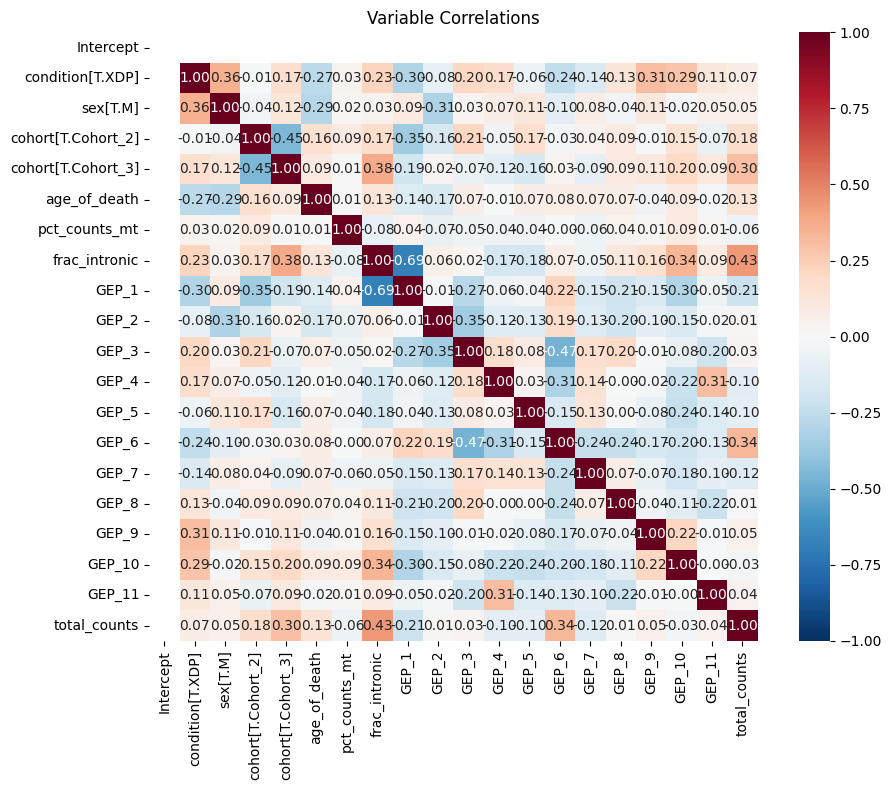

              variable         VIF
0            Intercept  454.428966
8                GEP_1    3.512382
13               GEP_6    3.425556
17              GEP_10    3.287417
7        frac_intronic    3.090422
10               GEP_3    3.036451
3   cohort[T.Cohort_2]    2.419522
4   cohort[T.Cohort_3]    2.316342
9                GEP_2    2.189153
1     condition[T.XDP]    2.146171
15               GEP_8    1.992460
18              GEP_11    1.940032
2             sex[T.M]    1.797399
19        total_counts    1.769930
11               GEP_4    1.618296
12               GEP_5    1.604853
5         age_of_death    1.414939
14               GEP_7    1.398770
16               GEP_9    1.358837
6        pct_counts_mt    1.068489

binary identifiability test. False
ATTENTION: using lmerTest (Gaussian LMM) --> not totally statistically correct (but still robust) 
		 ZIBR coudl be better


2026-04-21 19:34:31 | [WARNING] R callback write-console: condition: factor | example: XDP
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: donor_id: character | example: SCF-20-025
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: age_of_death: numeric | example: 54
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: sex: character | example: M
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.0557931932304259
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.755158437730287
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: GEP_1: numeric | example: 0.0359584308558179
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: GEP_2: numeric | example: 0.0213649584161421
  
2026-04-21 19:34:31 | [WARNING] R callback write-console: GEP_3: numeric | exam

factor     beta       se      p_value          fdr
GEP_10 0.151504 0.022994 7.520151e-08 8.272167e-07
 GEP_8 0.115005 0.020670 2.057815e-06 1.131798e-05
 GEP_9 0.085614 0.016801 8.757385e-06 3.211041e-05
 GEP_3 0.130682 0.028740 4.910388e-05 1.350357e-04
 GEP_4 0.048444 0.011817 2.027215e-04 4.459873e-04
 GEP_6 0.072318 0.021075 1.393152e-03 2.554112e-03
 GEP_2 0.066116 0.022352 5.192771e-03 8.160068e-03
GEP_11 0.073669 0.028356 1.309143e-02 1.800072e-02
 GEP_5 0.042169 0.017131 1.811277e-02 2.213784e-02
 GEP_1 0.019373 0.017016 2.614909e-01 2.876400e-01
 GEP_7 0.011769 0.016703 4.850364e-01 4.850364e-01
Significant GEPs (FDR<0.05): ['GEP_10', 'GEP_8', 'GEP_9', 'GEP_3', 'GEP_4', 'GEP_6', 'GEP_2', 'GEP_11', 'GEP_5']
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting condition reference level to: Control
Levels: Control XDP 
[1] "Creating Seurat object..."


2026-04-21 19:34:41 | [WARNING] R callback write-console: Warning:  
2026-04-21 19:34:41 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/3/Striatum_combined_QC_mmc_ct-cured_zoned.qs', '--id-col', 'donor_id', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/3/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/3/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col t

/home/gdallagl/myworkdir/XDP/utils/nebula_with_factors.py:461: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(CONTRAST_VARIABLE)[SAMPLE_VARIABLE]


Saved healthy GEP projections: 1312 cells, 11 GEPs
Running Factor calculation on Diseased...
Saved diseased GEP projections: 4280 cells, 11 GEPs
Saving h5ad file...
adata intact: 5592 cells, 10209 genes
ATTENTION: Dropping 0 cells with NaN covariates: []


... storing 'ct_for_deg' as categorical


~ condition + age_of_death + sex + pct_counts_mt + frac_intronic + cohort + GEP_1 + GEP_2 + GEP_3 + GEP_4 + GEP_5 + GEP_6 + GEP_7 + GEP_8 + GEP_9 + GEP_10 + GEP_11 + total_counts


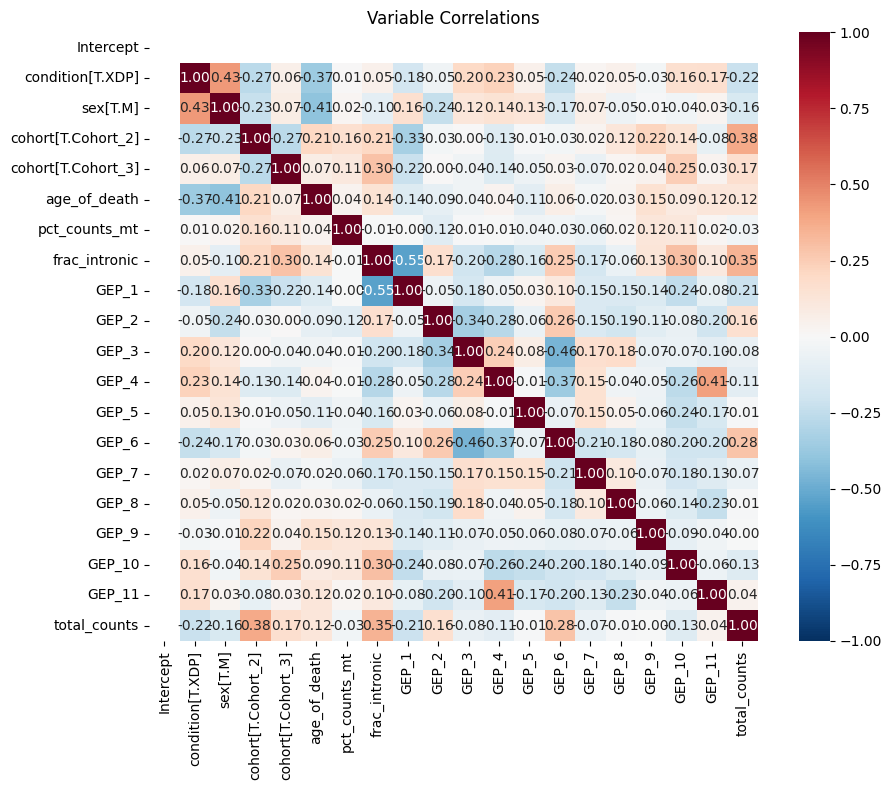

              variable         VIF
0            Intercept  486.673461
17              GEP_10    4.300714
13               GEP_6    3.425875
8                GEP_1    2.885106
18              GEP_11    2.831654
10               GEP_3    2.618694
9                GEP_2    2.539330
3   cohort[T.Cohort_2]    2.436916
7        frac_intronic    2.345063
1     condition[T.XDP]    2.341355
11               GEP_4    2.232498
15               GEP_8    2.212241
16               GEP_9    2.033877
4   cohort[T.Cohort_3]    1.803249
19        total_counts    1.789805
2             sex[T.M]    1.705913
5         age_of_death    1.605347
14               GEP_7    1.602188
12               GEP_5    1.435254
6        pct_counts_mt    1.124203

binary identifiability test. False
ATTENTION: using lmerTest (Gaussian LMM) --> not totally statistically correct (but still robust) 
		 ZIBR coudl be better


2026-04-21 19:36:19 | [WARNING] R callback write-console: condition: factor | example: XDP
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: donor_id: character | example: SCF_22-043
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: age_of_death: numeric | example: 52
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: sex: character | example: M
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: pct_counts_mt: numeric | example: 0.0159438775510204
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: frac_intronic: numeric | example: 0.720992728422384
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: cohort: character | example: Cohort_1
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: GEP_1: numeric | example: 0.101918516763011
  
2026-04-21 19:36:19 | [WARNING] R callback write-console: GEP_2: numeric | example: 0.0134213381600337
  
2026-04-21 19:36:20 | [WARNING] R callback write-console: GEP_3: numeric | examp

factor     beta       se  p_value      fdr
GEP_10 0.152740 0.028352 0.000003 0.000038
 GEP_8 0.113635 0.023620 0.000022 0.000119
 GEP_9 0.105576 0.025091 0.000140 0.000512
 GEP_4 0.058038 0.014428 0.000251 0.000689
 GEP_3 0.116588 0.031431 0.000623 0.001371
 GEP_6 0.076784 0.021235 0.000814 0.001388
 GEP_5 0.059646 0.016629 0.000883 0.001388
 GEP_7 0.058060 0.018049 0.002548 0.003504
GEP_11 0.082627 0.026708 0.003551 0.004340
 GEP_2 0.063327 0.025264 0.016283 0.017911
 GEP_1 0.037170 0.019718 0.066407 0.066407
Significant GEPs (FDR<0.05): ['GEP_10', 'GEP_8', 'GEP_9', 'GEP_4', 'GEP_3', 'GEP_6', 'GEP_5', 'GEP_7', 'GEP_11', 'GEP_2']
Saving qs file...
	Saving files for R coversion...
	Building R obj...

Setting condition reference level to: Control
Levels: Control XDP 
[1] "Creating Seurat object..."


2026-04-21 19:36:30 | [WARNING] R callback write-console: Warning:  
2026-04-21 19:36:30 | [WARNING] R callback write-console:  Data is of class dgTMatrix. Coercing to dgCMatrix.
  


[1] "Saving Seurat object as .qs..."
Running Nebula...
cmd list: ['bash', '/home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh', '--path', '/home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/4/Striatum_combined_QC_mmc_ct-cured_zoned.qs', '--id-col', 'donor_id', '--offset-col', 'total_counts', '--n-folds', '40', '--n-cores', '40', '--save-tmp', '0']
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/4/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col total_counts --n-folds 40 --n-cores 40 --save-tmp 0
Running command: bash /home/gdallagl/myworkdir/XDP/utils/nebula_scripts/run-nebula-parallel.sh --path /home/gdallagl/myworkdir/XDP/data/XDP/NucSec/DEG/Striatum/cNMF_nebula/Astrocyte_by_zone_4/4/Striatum_combined_QC_mmc_ct-cured_zoned.qs --id-col donor_id --offset-col t

: 

In [ ]:
for zone_ct, zone_variable in ZONE_CT_MAP.items():

    # if zone_ct != "Astrocyte":
    #     continue
    
    if zone_ct not in adata.obs["ct_for_deg"].values:
        print(f"WARNING: {zone_ct} not in adata, skipping")
        continue

    # cNMF of celltype_X_zone are not recualted (ie re-facotrize for each zone)
    #  we just use the same cNMF spectra as for the whole cell type, but run Nebula separately for each zone (with the zone as a covariate in the model)
        # Reuse the spectra from the full cell-type cNMF run (already computed)
    if TYPE_DEG == "cNMF_nebula":
        matches = glob.glob(f"{DEG_FOLDER}/{zone_ct}/cNMF_run_healthy/*.spectra.*.consensus.txt")
        if len(matches) != 1:
            print(f"WARNING: Expected 1 spectra file for {zone_ct}, found {len(matches)}: {matches}. Skipping.")
            continue
        CNMF_SPECTRA_PATH = matches[0]
        print(f"Using spectra: {CNMF_SPECTRA_PATH}")
    else:
        CNMF_SPECTRA_PATH = None

    adata_zone = adata[
        (adata.obs["ct_for_deg"] == zone_ct) & # filter to QC labels
        (adata.obs[zone_variable].notna()) # only cells with zone annotation
    ].to_memory().copy()

    for zone in sorted(adata_zone.obs[zone_variable].unique()):
        print(f"\n\n######################\n{zone_ct} / {zone_variable}={zone} / {TYPE_DEG}\n######################\n")

        adata_ct = adata_zone[adata_zone.obs[zone_variable] == zone].to_memory().copy()
        adata_ct.X = adata_ct.layers["counts"].copy()

        subfolder = f"{zone_ct}_by_{zone_variable}/{zone}"
        ADATA_PATH_QS = f"{DEG_FOLDER}/{subfolder}/{os.path.splitext(os.path.basename(ADATA_PATH))[0]}.qs"
        SAVE_HEALTHY_PCA_RESULT = os.path.dirname(ADATA_PATH_QS)
        os.makedirs(SAVE_HEALTHY_PCA_RESULT, exist_ok=True)
        print(SAVE_HEALTHY_PCA_RESULT)

        nebula_utils.run_nebula_with_factors(
            adata_ct,
            ADATA_PATH_QS, SAVE_HEALTHY_PCA_RESULT, PARALLEL_NEBULA_SCRIPT_PATH,
            CONTRAST_VARIABLE, CONTRAST_BASELINE, CONTRAST_STIM,
            SAMPLE_VARIABLE, LIBRARY_SIZE_COL, COVARIATES_FOR_DEG,
            N_PCS_TO_USE=None, variance_threshold=None, delete_tmp_files=True, TYPE_DEG=TYPE_DEG,
            MIN_SAMPLES_PER_CONDITION=4, MIN_NUMBER_GENES_PER_ANALYSIS=3000,
            CNMF_SPECTRA_PATH=CNMF_SPECTRA_PATH
        )


    #break


#

# ---